# **Exercicio Duelo de Modelos 4**

Nesta tarefa, vocês irão criar o seu próprio duelo de modelos, com o objetivo de superar os resultados apresentados em aula. O desafio é alcançar um desempenho superior ao que obtivemos, e para isso, será necessário aplicar todas as melhorias que vocês aprenderam ao longo dos módulos, utilizando a base de dados do Titanic.

**1. Escolha do Modelo:**
Selecione um dos modelos que foram explorados nos duelos de modelos ao longo do curso. Pode ser SVM, Random Forest, XGBoost, ou qualquer outro que tenhamos abordado.

**2. Aperfeiçoamento:**
**Aplique as técnicas que aprendemos para melhorar o desempenho do seu modelo:**

**Hiperparâmetros:** Utilize GridSearchCV ou RandomSearchCV para encontrar os melhores parâmetros.

**Cross Validation:** Avalie a robustez do modelo utilizando validação cruzada para garantir que ele generaliza bem.

**Balanceamento de Classes:** Se o seu modelo lida com problemas de classes desbalanceadas, explore técnicas como SMOTE, undersampling ou oversampling.

**Padronização e Normalização:** Lembre-se de padronizar os dados, especialmente se for usar modelos que são sensíveis à escala das variáveis.

**3. Submissão no Kaggle:**
Treine o seu modelo com os dados de treino e gere as previsões para os dados de teste. Lembre-se de que o conjunto de teste não possui a variável alvo (y_test), pois a avaliação será feita com base nas submissões no Kaggle.
Submeta suas previsões na competição do Titanic no Kaggle.

**4. Entrega:**
Envie o código que você desenvolveu, detalhando cada etapa do seu processo de modelagem, explicando as escolhas feitas e como essas ajudaram a melhorar o modelo.

Junto com o código, envie um print do seu score obtido na plataforma do Kaggle. Esse score será a sua métrica final de avaliação, mostrando como o seu modelo se compara com os demais.

**5. Competição Saudável:**
A ideia é trazer um senso de competição saudável, então não vale replicar exatamente o que fizemos na aula! Inove, explore novas combinações de parâmetros e técnicas, e mostre do que é capaz. O importante é exercitar o pensamento crítico e a capacidade de experimentar.

**Dicas Finais:**

Seja criativo e tenha um olhar crítico sobre o que pode ser melhorado.
Teste diferentes abordagens e não se prenda a um único caminho.
Lembre-se de que, mais do que alcançar o melhor score, o objetivo é aprender e aplicar o conhecimento de forma prática e eficaz.
Boa sorte! Estamos ansiosos para ver como cada um de vocês vai se sair nesse desafio e quais insights irão surgir dessa competição!

Ao final dessa atividade vocês terão participado da primeira competição publica de ciência de dados de vocês = )




## 1 - Importação das Bibliotecas e carregamento da base de dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

In [2]:
# Carregamento das bases de dados de treino e teste
train_df = pd.read_csv('train.csv')
teste_df = pd.read_csv('test.csv')

In [3]:
# Exibição da base treino com a variável target
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Exibição da base teste que possue somente as features
teste_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 2 - Análise e tratamento dos dados

### A) Tipo de dados

In [5]:
# Análise dos tipos de dados da base de treino
train_df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [6]:
# Análise dos tipos de dados da base de teste
teste_df.dtypes

PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

As bases de dados de treino e teste apresentam estruturas e tipos de dados consistentes, divergindo exclusivamente pela presença da variável alvo (**target**) "`Survived`", contida apenas no conjunto de treino conforme as especificações do desafio.

A análise exploratória inicial identificou cinco variáveis qualitativas (do tipo **object**): `Name`, `Sex`, `Ticket`, `Cabin` e `Embarked`. As variáveis estritamente textuais — `Name` e `Ticket` — serão descartadas nesta etapa de modelagem. Por funcionarem essencialmente como identificadores de texto sem padrão estatístico direto, a permanência delas geraria ruído e não agregaria poder de generalização para os algoritmos.

Para o tratamento das variáveis categóricas remanescentes, foram adotadas abordagens distintas com base em suas características:
- `Sex`: Sendo uma variável binária (duas categorias), será transformada via Label Encoding, mapeando-a diretamente para valores 0 e 1.
- `Embarked`: Por apresentar três categorias distintas, será tratada com One-Hot Encoding (codificação binária dummy), evitando que o modelo presuma uma ordem hierárquica inexistente entre os portos de embarque.
- `Cabin`: Devido ao grande volume de dados nulos e alta fragmentação, aplicou-se uma técnica de engenharia de recursos para extrair a letra inicial de cada registro, que corresponde ao convés ocupado pelo passageiro. Posteriormente, essa nova estrutura será codificada via One-Hot Encoding, permitindo que o modelo capture o impacto da localização espacial no navio sobre a taxa de sobrevivência, sem perda drástica de representatividade dos dados.

In [7]:
# Exclusão das variáveis "Name e Ticket"
train_df = train_df.drop(['Name', 'Ticket'], axis=True)
teste_df = teste_df.drop(['Name', 'Ticket'], axis=True)

In [8]:
# Transformação da variável "Sex" com Label Encoder
# Chamando a função Label Encoder
label_encoder = LabelEncoder()

# Aplicação do Label Encoder nas coluas categóricas "Sex"
train_df['Sex'] = label_encoder.fit_transform(train_df['Sex'])
teste_df['Sex'] = label_encoder.fit_transform(teste_df['Sex'])

In [9]:
# Verificação dos dados presentes na base de dados de treino e teste na variável "Cabin"
dados_cabine_train = train_df['Cabin'].unique()
dados_cabine_teste = teste_df['Cabin'].unique()

print(f'Dados presente na variável "Cabin" da base de dados treino:\n {dados_cabine_train}\n')
print(f'Dados presente na variável "Cabin" da base de dados teste:\n {dados_cabine_teste}')

Dados presente na variável "Cabin" da base de dados treino:
 [nan 'C85' 'C123' 'E46' 'G6' 'C103' 'D56' 'A6' 'C23 C25 C27' 'B78' 'D33'
 'B30' 'C52' 'B28' 'C83' 'F33' 'F G73' 'E31' 'A5' 'D10 D12' 'D26' 'C110'
 'B58 B60' 'E101' 'F E69' 'D47' 'B86' 'F2' 'C2' 'E33' 'B19' 'A7' 'C49'
 'F4' 'A32' 'B4' 'B80' 'A31' 'D36' 'D15' 'C93' 'C78' 'D35' 'C87' 'B77'
 'E67' 'B94' 'C125' 'C99' 'C118' 'D7' 'A19' 'B49' 'D' 'C22 C26' 'C106'
 'C65' 'E36' 'C54' 'B57 B59 B63 B66' 'C7' 'E34' 'C32' 'B18' 'C124' 'C91'
 'E40' 'T' 'C128' 'D37' 'B35' 'E50' 'C82' 'B96 B98' 'E10' 'E44' 'A34'
 'C104' 'C111' 'C92' 'E38' 'D21' 'E12' 'E63' 'A14' 'B37' 'C30' 'D20' 'B79'
 'E25' 'D46' 'B73' 'C95' 'B38' 'B39' 'B22' 'C86' 'C70' 'A16' 'C101' 'C68'
 'A10' 'E68' 'B41' 'A20' 'D19' 'D50' 'D9' 'A23' 'B50' 'A26' 'D48' 'E58'
 'C126' 'B71' 'B51 B53 B55' 'D49' 'B5' 'B20' 'F G63' 'C62 C64' 'E24' 'C90'
 'C45' 'E8' 'B101' 'D45' 'C46' 'D30' 'E121' 'D11' 'E77' 'F38' 'B3' 'D6'
 'B82 B84' 'D17' 'A36' 'B102' 'B69' 'E49' 'C47' 'D28' 'E17' 'A24' 'C5

In [10]:
# Extração da primeira letra da variável "Cabin" e subtituição de valores nulos por "U"
# Definição da extração das letras inicias das variáveis, assim como a substituição dos valor nulos por "U"
def extracao(variavel):
    var_teste = []
    for x in variavel:
        if str(x) == 'nan':
            var_teste.append('U')
        else:
            var_teste.append(str(x)[0])
    return var_teste

# Extração e substituição dos dados na base
train_df['Cabin'] =  extracao(train_df['Cabin'])
teste_df['Cabin'] = extracao(teste_df['Cabin'])

print(f'Exibição da susbtituição da base de treino: \n{train_df['Cabin']}\n')
print(f'Exibição da susbtituição da base de teste: \n{teste_df['Cabin']}')

Exibição da susbtituição da base de treino: 
0      U
1      C
2      U
3      C
4      U
      ..
886    U
887    B
888    U
889    C
890    U
Name: Cabin, Length: 891, dtype: object

Exibição da susbtituição da base de teste: 
0      U
1      U
2      U
3      U
4      U
      ..
413    U
414    C
415    U
416    U
417    U
Name: Cabin, Length: 418, dtype: object


In [11]:
# Transformação das variáveis "Embarked e Cabin" com One-Hot Encoding e exclusão das variáveis do tipo object
train_df = pd.get_dummies(train_df, columns=['Embarked', 'Cabin'], prefix=['Embarked', 'Cabin'])
teste_df = pd.get_dummies(teste_df, columns=['Embarked', 'Cabin'], prefix=['Embarked', 'Cabin'])


In [12]:
# Conferência dos tipos de dados da base de treino
train_df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_T           bool
Cabin_U           bool
dtype: object

In [13]:
# Conferência dos tipos de dados da base de teste
teste_df.dtypes

PassengerId      int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_U           bool
dtype: object

### B) Valores nulos

In [14]:
# Verificação do total de valores nulos nas bases de treino
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
Embarked_C       0
Embarked_Q       0
Embarked_S       0
Cabin_A          0
Cabin_B          0
Cabin_C          0
Cabin_D          0
Cabin_E          0
Cabin_F          0
Cabin_G          0
Cabin_T          0
Cabin_U          0
dtype: int64

In [15]:
# Verificação da porcentagem de valores nulos nas bases de treino
train_df.isnull().mean()

PassengerId    0.000000
Survived       0.000000
Pclass         0.000000
Sex            0.000000
Age            0.198653
SibSp          0.000000
Parch          0.000000
Fare           0.000000
Embarked_C     0.000000
Embarked_Q     0.000000
Embarked_S     0.000000
Cabin_A        0.000000
Cabin_B        0.000000
Cabin_C        0.000000
Cabin_D        0.000000
Cabin_E        0.000000
Cabin_F        0.000000
Cabin_G        0.000000
Cabin_T        0.000000
Cabin_U        0.000000
dtype: float64

In [16]:
# Verificação de valores nulos nas bases de teste
teste_df.isnull().sum()

PassengerId     0
Pclass          0
Sex             0
Age            86
SibSp           0
Parch           0
Fare            1
Embarked_C      0
Embarked_Q      0
Embarked_S      0
Cabin_A         0
Cabin_B         0
Cabin_C         0
Cabin_D         0
Cabin_E         0
Cabin_F         0
Cabin_G         0
Cabin_U         0
dtype: int64

In [17]:
# Verificação da porcentagem de valores nulos nas bases de teste
teste_df.isnull().mean()

PassengerId    0.000000
Pclass         0.000000
Sex            0.000000
Age            0.205742
SibSp          0.000000
Parch          0.000000
Fare           0.002392
Embarked_C     0.000000
Embarked_Q     0.000000
Embarked_S     0.000000
Cabin_A        0.000000
Cabin_B        0.000000
Cabin_C        0.000000
Cabin_D        0.000000
Cabin_E        0.000000
Cabin_F        0.000000
Cabin_G        0.000000
Cabin_U        0.000000
dtype: float64

O mapeamento de dados ausentes indicou que apenas as variáveis numéricas `Age` e `Fare` demandam tratamento, apresentando os seguintes índices de vacância:

- `Age`: Apresenta 19,8% de dados nulos na base de treino e 20,5% na base de teste.
- `Fare`:  Apresenta uma taxa residual de apenas 0,2% no conjunto de teste e 0% na base de treino. Por se tratar de um volume extremamente baixo em comparação ao total de registros, essa ausência é considerada estatisticamente irrelevante, permitindo uma correção segura.

Para corrigir essas omissões sem comprometer o volume amostral do dataset, será aplicado a estratégia de imputação pela média. Essa abordagem preenche as lacunas estatísticas de ambas as colunas, preservando a integridade estrutural das tabelas e garantindo a estabilidade necessária para a execução dos modelos.

In [18]:
# Preenchimento dos valores nulos das variáveis "Age e Fare" das bases de dados de treino e teste com a média
# Train
train_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
train_df['Fare'].fillna(train_df['Fare'].mean(), inplace=True)

# Teste
teste_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
teste_df['Fare'].fillna(teste_df['Fare'].mean(), inplace=True)

C:\Users\nneto\AppData\Local\Temp\ipykernel_18412\4260478402.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
C:\Users\nneto\AppData\Local\Temp\ipykernel_18412\4260478402.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a co

In [19]:
# Confêrencia de valores nulos na bases de treino
train_df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
Cabin_A        0
Cabin_B        0
Cabin_C        0
Cabin_D        0
Cabin_E        0
Cabin_F        0
Cabin_G        0
Cabin_T        0
Cabin_U        0
dtype: int64

In [20]:
# Confêrencia de valores nulos na bases de teste
teste_df.isnull().sum()

PassengerId    0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
Cabin_A        0
Cabin_B        0
Cabin_C        0
Cabin_D        0
Cabin_E        0
Cabin_F        0
Cabin_G        0
Cabin_U        0
dtype: int64

### C) Outliers

In [21]:
# Verifição rápida e inicial para identificar a presença de Outliers na base de treino
train_df.describe()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,0.647587,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,0.477990,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,1.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200


In [22]:
# Verifição rápida e inicial para identificar a presença de Outliers na base de teste
teste_df.describe()

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000
mean,1100.500000,2.265550,0.636364,30.154603,0.447368,0.392344,35.627188
std,120.810458,0.841838,0.481622,12.636666,0.896760,0.981429,55.840500
min,892.000000,1.000000,0.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,0.000000,23.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,1.000000,29.699118,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,1.000000,35.750000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,1.000000,76.000000,8.000000,9.000000,512.329200


A análise descritiva dos conjuntos de treino e teste revela distribuições consistentes e sem discrepâncias que indiquem erros de registro ou anomalias nos dados. Variáveis contínuas como `Age` (com máxima de 80 anos no treino e 76 no teste) e `Fare` (com máxima de 512.33 em ambas as bases) exibem variações acentuadas, porém plenamente justificáveis pelo contexto histórico e socioeconômico dos passageiros, representando a variabilidade natural do fenômeno real (como passagens de primeira classe de alto luxo). Dado que essas flutuações refletem o comportamento legítimo da população do navio, optou-se por não aplicar métodos agressivos de análise (boxplot), remoção ou tratamento de outliers. Essa decisão preserva a integridade e a riqueza estatística dos dados, permitindo que os modelos capturem nuances importantes sobre o perfil socioeconômico dos sobreviventes.

### D) Verificação de correlação das variáveis

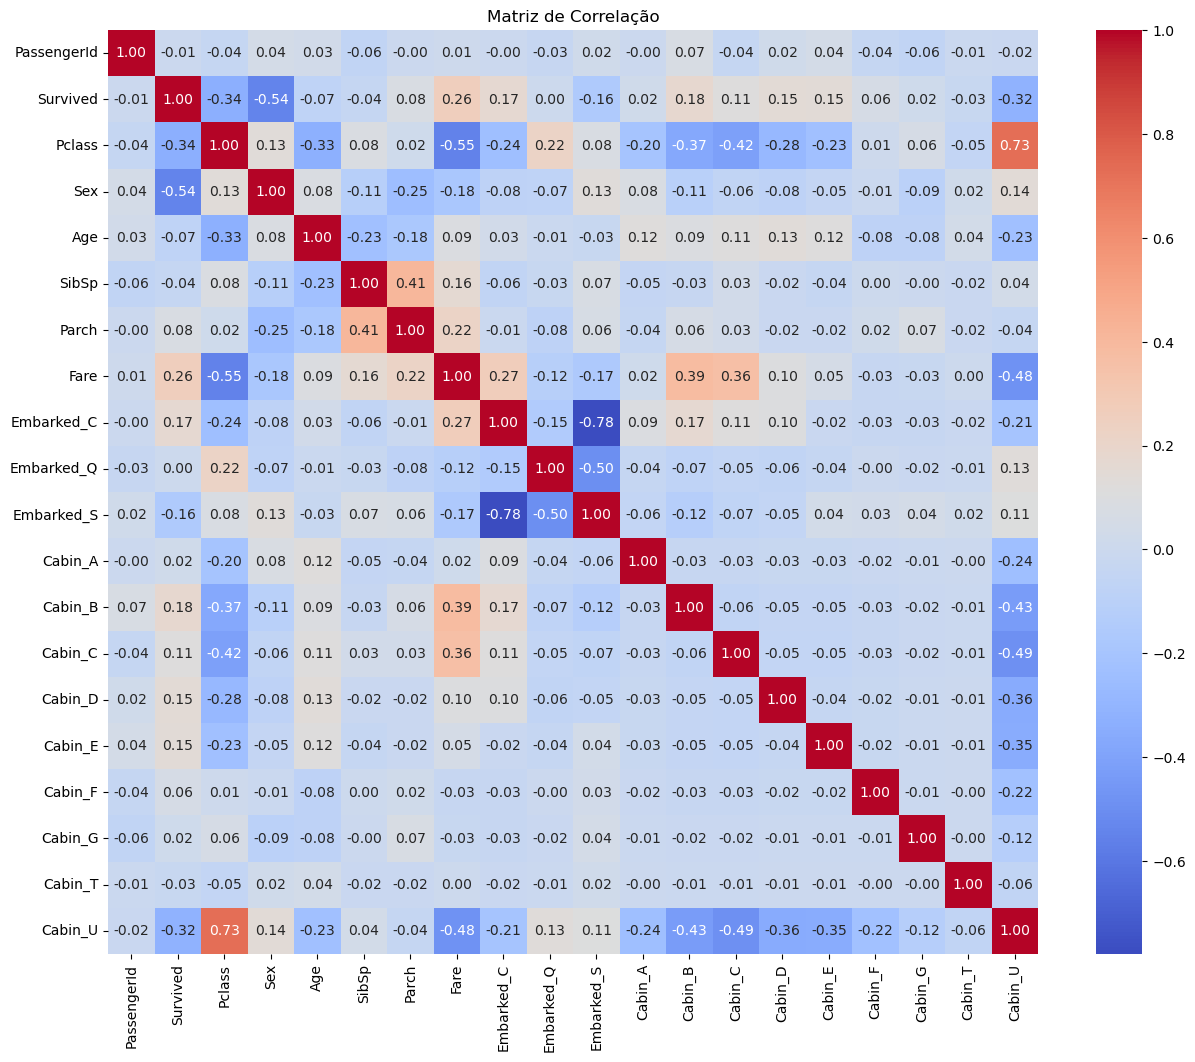

In [23]:
# Verificação da correlação entre as variáveis da base de treino
var_corr = train_df.corr()

# Exibição da matriz de correlação
plt.figure(figsize=(15, 12))
sns.heatmap(var_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

A análise da matriz de correlação linear permitiu identificar associações relevantes entre as variáveis preditoras e a variável alvo (`Survived`), fornecendo uma primeira visão sobre quais características dos passageiros apresentam maior relação com a sobrevivência.

Os principais pontos observados foram:
- **Gênero** (`Sex`): apresentou a correlação mais forte com a sobrevivência (-0,54). O sinal negativo está relacionado à codificação utilizada para a variável e indica uma forte associação entre gênero e sobrevivência. Esse resultado é consistente com os registros históricos do desastre, nos quais mulheres apresentaram maiores taxas de sobrevivência.
- **Classe socioeconômica** (`Pclass`): apresentou correlação negativa relevante (-0,34). Como a variável é codificada de forma ordinal, valores maiores representam classes inferiores, indicando uma associação entre a classe do passageiro e sua probabilidade de sobrevivência.
- **Ausência de cabine identificada** (`Cabin_U`): apresentou correlação negativa de -0,32 com `Survived` e forte correlação de 0,73 com `Pclass`. Esse resultado sugere que a ausência de informação sobre a cabine pode estar funcionando como um indicador indireto das características socioeconômicas dos passageiros, especialmente por sua associação com passageiros de classes inferiores. Portanto, `Cabin_U` deve ser interpretada como uma variável relacionada à disponibilidade/ausência da informação de cabine, e não diretamente como uma medida de luxo.
- **Tarifa** (`Fare`) **e cabines de classes superiores**: `Fare` apresentou correlação positiva moderada (0,26), enquanto algumas categorias de cabine, como `Cabin_B` (0,18), `Cabin_D` (0,15) e `Cabin_E` (0,15), também apresentaram associações positivas com a sobrevivência. Esses resultados são compatíveis com a relação existente entre tarifa, localização da cabine e classe socioeconômica.
- **Variáveis com baixa correlação linear**: `PassengerId`, `Age` e `Embarked_Q` apresentaram correlações próximas de zero ou de baixa magnitude. Entretanto, uma baixa correlação linear não significa necessariamente que essas variáveis sejam irrelevantes para a modelagem. Uma variável pode apresentar relações não lineares ou interações com outras características que não sejam capturadas pela correlação de Pearson. Por esse motivo, sua utilidade será verificada também durante a etapa de modelagem.

A matriz de correlação também revelou relações importantes entre algumas variáveis preditoras. Um exemplo é a forte correlação entre `Pclass` e `Cabin_U` (0,73), indicando que essas variáveis carregam informações parcialmente relacionadas. Esse aspecto será considerado durante a construção e avaliação dos modelos.

**Estratégia de Modelagem**

Com base nesses resultados, serão desenvolvidos dois cenários de modelagem para comparar o desempenho dos algoritmos.

**1. Cenário completo**

Será utilizado o conjunto completo de variáveis preditoras após o tratamento dos dados, incluindo aquelas que apresentaram baixa correlação linear com `Survived`.

O objetivo é avaliar a capacidade dos modelos de utilizar diferentes características simultaneamente e verificar se variáveis com baixa associação linear individual podem contribuir para a previsão por meio de relações não lineares ou interações.

**2. Cenário selecionado**

Será utilizado um conjunto reduzido de variáveis, priorizando aquelas que apresentaram maior associação com `Survived` e possuem justificativa teórica relevante, como `Sex`, `Pclass`, `Fare` e as principais categorias de `Cabin`.

O objetivo é verificar se a redução das variáveis pode diminuir informações pouco relevantes ou redundantes e, consequentemente, melhorar a capacidade de generalização dos modelos.

A comparação entre os dois cenários permitirá testar empiricamente a hipótese de que um conjunto mais enxuto de variáveis pode apresentar melhor desempenho. No entanto, a seleção não será baseada exclusivamente na correlação linear, pois os modelos podem identificar padrões que não são necessariamente evidenciados pela matriz de correlação.

Dessa forma, a definição do conjunto de variáveis será validada posteriormente por meio das métricas de desempenho dos modelos e da validação cruzada, permitindo avaliar não apenas a associação estatística individual das variáveis, mas também sua contribuição efetiva para a capacidade preditiva.

### E) Separação das variáveis dependentes (Y) e independentes (X) para o desenvolvimento de cenários completos e selecionados no conjunto de treino e teste

In [24]:
# Separação das variáveis completas
X_train_complet = train_df.drop(columns='Survived', axis=1)
X_test_complet = teste_df
y_train = train_df['Survived']

# Separação das variáveis selecionadas
# Definição das variáveis que serão utilizadas
var_select = ['Sex', 'Pclass', 'Fare', 'Cabin_U', 'Cabin_B', 'Embarked_C',
              'Embarked_S', 'Cabin_D', 'Cabin_E', 'Cabin_C'] 
X_train_select = train_df[var_select]
X_test_select = train_df[var_select]

In [25]:
# Verificação da divisão "X_train_complet"
X_train_complet

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_T,Cabin_U
0,1,3,1,22.000000,1,0,7.2500,False,False,True,False,False,False,False,False,False,False,False,True
1,2,1,0,38.000000,1,0,71.2833,True,False,False,False,False,True,False,False,False,False,False,False
2,3,3,0,26.000000,0,0,7.9250,False,False,True,False,False,False,False,False,False,False,False,True
3,4,1,0,35.000000,1,0,53.1000,False,False,True,False,False,True,False,False,False,False,False,False
4,5,3,1,35.000000,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,1,27.000000,0,0,13.0000,False,False,True,False,False,False,False,False,False,False,False,True
887,888,1,0,19.000000,0,0,30.0000,False,False,True,False,True,False,False,False,False,False,False,False
888,889,3,0,29.699118,1,2,23.4500,False,False,True,False,False,False,False,False,False,False,False,True
889,890,1,1,26.000000,0,0,30.0000,True,False,False,False,False,True,False,False,False,False,False,False


In [26]:
# Verificação da divisão "X_test_complet"
X_test_complet

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_U
0,892,3,1,34.500000,0,0,7.8292,False,True,False,False,False,False,False,False,False,False,True
1,893,3,0,47.000000,1,0,7.0000,False,False,True,False,False,False,False,False,False,False,True
2,894,2,1,62.000000,0,0,9.6875,False,True,False,False,False,False,False,False,False,False,True
3,895,3,1,27.000000,0,0,8.6625,False,False,True,False,False,False,False,False,False,False,True
4,896,3,0,22.000000,1,1,12.2875,False,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,1,29.699118,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,True
414,1306,1,0,39.000000,0,0,108.9000,True,False,False,False,False,True,False,False,False,False,False
415,1307,3,1,38.500000,0,0,7.2500,False,False,True,False,False,False,False,False,False,False,True
416,1308,3,1,29.699118,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,True


In [27]:
# Verificação da divisão "X_train_select"
X_train_select

,Sex,Pclass,Fare,Cabin_U,Cabin_B,Embarked_C,Embarked_S,Cabin_D,Cabin_E,Cabin_C
0,1,3,7.2500,True,False,False,True,False,False,False
1,0,1,71.2833,False,False,True,False,False,False,True
2,0,3,7.9250,True,False,False,True,False,False,False
3,0,1,53.1000,False,False,False,True,False,False,True
4,1,3,8.0500,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
886,1,2,13.0000,True,False,False,True,False,False,False
887,0,1,30.0000,False,True,False,True,False,False,False
888,0,3,23.4500,True,False,False,True,False,False,False
889,1,1,30.0000,False,False,True,False,False,False,True


In [28]:
# Verificação da divisão "X_train_select"
X_test_select

,Sex,Pclass,Fare,Cabin_U,Cabin_B,Embarked_C,Embarked_S,Cabin_D,Cabin_E,Cabin_C
0,1,3,7.2500,True,False,False,True,False,False,False
1,0,1,71.2833,False,False,True,False,False,False,True
2,0,3,7.9250,True,False,False,True,False,False,False
3,0,1,53.1000,False,False,False,True,False,False,True
4,1,3,8.0500,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
886,1,2,13.0000,True,False,False,True,False,False,False
887,0,1,30.0000,False,True,False,True,False,False,False
888,0,3,23.4500,True,False,False,True,False,False,False
889,1,1,30.0000,False,False,True,False,False,False,True


In [29]:
# Verificação da variável dependente "y_train"
y_train

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

### F) Balanceamento e padronização dos dados

In [30]:
# Verificação do balancemanto dos dados
train_df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [31]:
# Inicialização do SMOTE (Balanceamento)
smote = SMOTE(random_state=42)

# Balanceamento dos dados completos
X_train_complet_balanced, y_train_balanced = smote.fit_resample(X_train_complet, y_train)

# Balancemento dos dados selecionados
X_train_select_balanced, y_train_balanced = smote.fit_resample(X_train_select, y_train)

c:\Users\nneto\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\nneto\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\nneto\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\nneto\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^

In [32]:
# Verificação do balanceamento dos dados
X_train_complet_balanced.shape, X_train_select_balanced.shape, y_train_balanced.shape

((1098, 19), (1098, 10), (1098,))

In [33]:
# Inicialização do StandardScaler (Padronização)
scaler = StandardScaler()

# Padronização dos dados de treino completo
X_train_complet_padro = scaler.fit_transform(X_train_complet_balanced)

# Padronização dos dados de teste completo
X_test_complet_padro = scaler.fit_transform(X_test_complet)

# Padronização dos dados de treino selecionado
X_train_select_padro = scaler.fit_transform(X_train_select_balanced)

# Padronização dos dados de teste selecionado
X_test_select_padro = scaler.fit_transform(X_train_select)

## 3 - Duelo entre modelos

A escolha dos modelos fundamenta-se no contraste entre duas filosofias matemáticas distintas para classificação binária. O Random Forest foi selecionado por ser um modelo baseado em comitês de árvores de decisão, altamente robusto contra overfitting e capaz de lidar nativamente com dados categóricos e ruídos. Já o SVM (Support Vector Machine) atua de forma geométrica, buscando encontrar o hiperplano ideal de separação com máxima margem entre as classes. Esse duelo permite avaliar qual arquitetura — uma baseada em regras de decisão agrupadas ou outra baseada em fronteiras espaciais complexas — apresenta melhor poder de generalização para os dados do Titanic.

### Random Forest

#### A) Cenário completo

##### Dados desbalanceados e despadronizados

In [34]:
# Inicialização do modelo Random Forest completo
rf_model_complet_dp = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1)

In [35]:
# Treinamento do modelo na base de treino completo
rf_model_complet_dp.fit(X_train_complet, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [36]:
# Previsão do modelo na base de treino completo
y_rf_train_pred_complet_dp = rf_model_complet_dp.predict(X_train_complet)

In [37]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_complet_dp = cross_val_score(rf_model_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo Random Forest com dados completos, desbalanceados e despadronizados
accuracy_complet_dp = accuracy_score(y_train, y_rf_train_pred_complet_dp)
report_complet_dp = classification_report(y_train, y_rf_train_pred_complet_dp)
confusion_matrix_complet_dp = confusion_matrix(y_train, y_rf_train_pred_complet_dp)
pontuacoes_complet_dp = cross_val_score(rf_model_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print("  RESULTADOS: RANDOM FOREST (COMPLETO, DESBALANCEADO, BRUTO)  ")
print('---' * 20)
print(f'Acurácia: {accuracy_complet_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_complet_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_complet_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_complet_dp.mean():.2f}')

  RESULTADOS: RANDOM FOREST (COMPLETO, DESBALANÇADO, BRUTO)  
------------------------------------------------------------
Acurácia: 1.00
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       549
           1       1.00      1.00      1.00       342

    accuracy                           1.00       891
   macro avg       1.00      1.00      1.00       891
weighted avg       1.00      1.00      1.00       891

------------------------------------------------------------
Matriz de Confusão: 
 [[549   0]
 [  0 342]]
------------------------------------------------------------
Média da Validação Cruzada: 0.81


In [39]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_complet_dp)

# Cálculo da AUC
roc_auc_complet_dp = roc_auc_score(y_train, y_rf_train_pred_complet_dp)
print('AUC: {:.2f}'.format(roc_auc_complet_dp))

AUC: 1.00


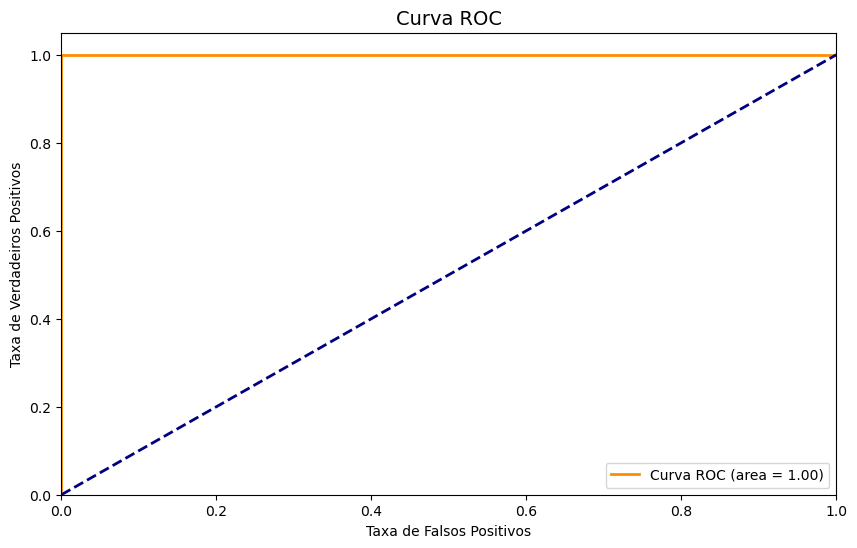

In [40]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
Os resultados iniciais do modelo Random Forest treinado com o conjunto de dados completo e hiperparâmetros padrão revelam um cenário de overfitting severo (sobreajuste).

Ao analisar as métricas de validação internas, o modelo atingiu uma Acurácia de 1.00, AUC-ROC de 1.00 e uma matriz de confusão perfeita, sem nenhum erro de classificação dentro do conjunto mapeado. No entanto, o indicador mais realista do real poder de generalização do algoritmo é revelado pela Validação Cruzada (Cross-Validation), que registrou uma média de 0.81.

Essa divergência acentuada (1.00 no treino vs. 0.81 na validação cruzada) ocorre porque, por padrão, o `RandomForestClassifier` não possui limite de profundidade para suas árvores (`max_depth=None`). Como consequência, o algoritmo memorizou perfeitamente os dados de treino, criando ramificações tão profundas que isolaram perfeitamente cada caso, perdendo a capacidade de generalizar de forma eficiente para novos dados do mundo real. Esse comportamento reforça a necessidade crucial do próximo processo do projeto: a tunagem de hiperparâmetros para controlar a complexidade das árvores e estabilizar o modelo.

##### Aplicação de hiperparâmetros no Random Forest com os dados desbalanceados e despadronizados

In [42]:
# Definição de hiperparâmetros para testes
param_grid_rf_complet_dp = {
    'n_estimators': [100, 200, 300],     # Quantidade de árvores
    'max_depth': [3, 5, 7, 10],          # Controla a profundidade máxima
    'min_samples_split': [5, 10, 20],   # Número mínimo de amostras para separar um nó
    'min_samples_leaf': [2, 4, 8],   # Número mínimo de amostras que devem ficar em cada folha
    'max_features': ['sqrt', 'log2']    # Quantidade de colunas sorteadas por árvore
}

In [43]:
# Configuração do Grid Search
grid_search_rf_complet_dp = GridSearchCV(
    estimator=rf_model_complet_dp,
    param_grid=param_grid_rf_complet_dp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

In [44]:
# Executando o Grid Search
grid_search_rf_complet_dp.fit(X_train_complet, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 4, 8],
                         'min_samples_split': [5, 10, 20],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy', verbose=1)

In [45]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_rf_complet_dp.best_params_)
print("Melhor score:", grid_search_rf_complet_dp.best_score_)

Melhores parâmetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 200}
Melhor score: 0.8361496453455526


In [46]:
# Treinamento do modelo com os melhores hiperparâmetros
best_rf_complet_dp = grid_search_rf_complet_dp.best_estimator_
best_rf_complet_dp.fit(X_train_complet, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=4, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [47]:
# Previsão do modelo na base de treino completo com os melhores hiperpâmetros
y_rf_train_pred_complet_dp_best = best_rf_complet_dp.predict(X_train_complet)

In [48]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp_best = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_complet_dp_best = cross_val_score(best_rf_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo Random Forest com dados completos, desbalanceados e despadronizados com aplicação de hiperparâmetros
accuracy_complet_dp_best = accuracy_score(y_train, y_rf_train_pred_complet_dp_best)
report_complet_dp_best = classification_report(y_train, y_rf_train_pred_complet_dp_best)
confusion_matrix_complet_dp_best = confusion_matrix(y_train, y_rf_train_pred_complet_dp_best)
pontuacoes_complet_dp_best = cross_val_score(best_rf_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp_best)

print("RESULTADOS: RANDOM FOREST (COMPLETO, DESBALANCEADO, BRUTO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {accuracy_complet_dp_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_complet_dp_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_complet_dp_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_complet_dp_best.mean():.2f}')

RESULTADOS: RANDOM FOREST (COMPLETO, DESBALANÇADO, BRUTO E COM HIPERPARÂMETROS)
------------------------------------------------------------
Acurácia: 0.89
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.87      0.96      0.91       549
           1       0.93      0.76      0.84       342

    accuracy                           0.89       891
   macro avg       0.90      0.86      0.87       891
weighted avg       0.89      0.89      0.88       891

------------------------------------------------------------
Matriz de Confusão: 
 [[528  21]
 [ 81 261]]
------------------------------------------------------------
Média da Validação Cruzada: 0.82


In [95]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_complet_dp_best)

# Cálculo da AUC
roc_auc_complet_dp_best = roc_auc_score(y_train, y_rf_train_pred_complet_dp_best)
print('AUC: {:.2f}'.format(roc_auc_complet_dp_best))

AUC: 0.86


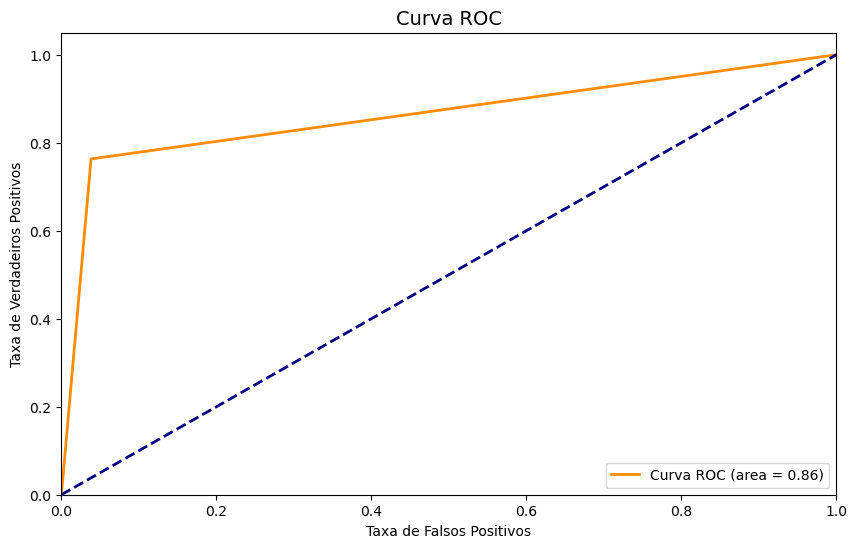

In [49]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_dp_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A aplicação do GridSearchCV encontrou a combinação ideal de restrições para controlar a complexidade das árvores, selecionando os seguintes parâmetros: max_depth: 10, min_samples_leaf: 4, min_samples_split: 5 e n_estimators: 200. Os impactos práticos dessa otimização refletem-se diretamente nas métricas obtidas:
- **Correção do Overfitting:** A acurácia na base de treino recuou de um valor irreal de 1.00 para 0.89. Essa queda na curva de treino é um excelente indicador técnico: mostra que o modelo parou de apenas memorizar os dados (decorar as linhas) e passou a aprender os padrões estatísticos reais.
- **Estabilidade Estatística:** O score médio do GridSearch atingiu 0.836 (83,6%) e a validação cruzada consolidou-se em 0.82. Como a acurácia de treino (0.89) ficou muito mais próxima da validação (0.82), o modelo demonstra excelente estabilidade e um poder de generalização muito superior para os dados de teste inéditos do Kaggle.
- **Métricas por Classe (F1-Score):** O modelo obteve um desempenho formidável na predição de não-sobreviventes (Classe 0), com F1-Score de 0.91 e Recall de 0.96 (errando apenas 21 passageiros). Para a classe de sobreviventes (Classe 1), o modelo manteve uma alta precisão de 0.93, embora com um Recall ligeiramente menor de 0.76 (81 falsos negativos), resultando em um F1-Score equilibrado de 0.84.
- **Análise da Curva ROC (AUC = 0.86):** A Área Sob a Curva (AUC) de 0.86 confirma graficamente a forte capacidade discriminatória do modelo otimizado. O gráfico demonstra que o algoritmo possui uma alta taxa de verdadeiros positivos logo no início, mantendo uma taxa controlada e baixa de falsos positivos.

##### Dados balanceados, padronizados e com os hiperparâmetros

In [52]:
# Treinamento do modelo balanceado e padronizado com os melhores hiperparâmetros
best_rf_complet = grid_search_rf_complet_dp.best_estimator_
best_rf_complet.fit(X_train_complet_padro, y_train_balanced)

RandomForestClassifier(max_depth=10, min_samples_leaf=4, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [53]:
# Previsão do modelo na base de treino completo, balanceado e padronizado com os melhores hiperpâmetros
y_rf_train_pred_complet_best = best_rf_complet.predict(X_train_complet_padro)

In [54]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_best = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_complet_best = cross_val_score(best_rf_complet, X_train_complet_padro, y_train_balanced, cv=folds)

In [55]:
# Avaliação do modelo Random Forest balanceado e padronizado com os melhores hiperpâmetros
accuracy_complet_best = accuracy_score(y_train_balanced, y_rf_train_pred_complet_best)
report_complet_best = classification_report(y_train_balanced, y_rf_train_pred_complet_best)
confusion_matrix_complet_best = confusion_matrix(y_train_balanced, y_rf_train_pred_complet_best)
pontuacoes_complet_best = cross_val_score(best_rf_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_complet_best)

print("RESULTADOS: RANDOM FOREST (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {accuracy_complet_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_complet_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_complet_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_complet_best.mean():.2f}')

RESULTADOS: RANDOM FOREST (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)
------------------------------------------------------------
Acurácia: 0.89
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.86      0.92      0.89       549
           1       0.91      0.85      0.88       549

    accuracy                           0.89      1098
   macro avg       0.89      0.89      0.89      1098
weighted avg       0.89      0.89      0.89      1098

------------------------------------------------------------
Matriz de Confusão: 
 [[505  44]
 [ 80 469]]
------------------------------------------------------------
Média da Validação Cruzada: 0.84


In [68]:
# Análise da curva AUC-ROC com os dados de treino completo, balanceados, padronizados e com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_rf_train_pred_complet_best)

# Cálculo da AUC
roc_auc_complet_best = roc_auc_score(y_train_balanced, y_rf_train_pred_complet_best)
print('AUC: {:.2f}'.format(roc_auc_complet_best))

AUC: 0.89


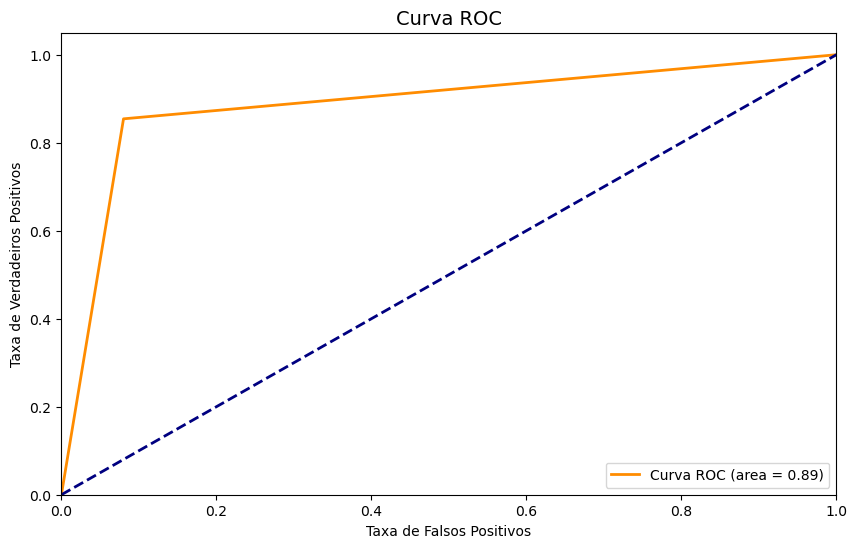

In [69]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A introdução do balanceamento e da padronização dos dados, combinada com os hiperparâmetros ajustados, trouxe uma evolução nítida para o modelo, consolidando uma Acurácia de 0.89 e elevando a Média da Validação Cruzada para 0.84 (um ganho real frente aos 0.82 anteriores).

O principal avanço ocorreu no equilíbrio entre as classes: o Recall dos sobreviventes (Classe 1) saltou de 0.76 para 0.85, mostrando que o balanceamento reduziu drasticamente os falsos negativos (de 81 para 80 em uma base de suporte muito maior, de 549 exemplos). Esse comportamento mais homogêneo é confirmado pelo F1-Score idêntico de 0.89 para ambas as classes. Graficamente, a Curva ROC com AUC de 0.89 valida a excelente capacidade do classificador em discriminar sobreviventes e não-sobreviventes, tornando esta versão o padrão mais competitivo e robusto até aqui.

#### B) Cenário selecionado

##### Dados desbalanceados e despadronizados

In [56]:
# Inicialização do modelo Random Forest selecionado
rf_model_select_dp = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1)

In [57]:
# Treinamento do modelo na base de treino selecionado
rf_model_select_dp.fit(X_train_select, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [58]:
# Previsão do modelo na base de treino selecionado
y_rf_train_pred_select_dp = rf_model_select_dp.predict(X_train_select)

In [59]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_select_dp = cross_val_score(rf_model_select_dp, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo Random Forest com dados selecionados, desbalanceados e despadronizados
accuracy_select_dp = accuracy_score(y_train, y_rf_train_pred_select_dp)
report_select_dp = classification_report(y_train, y_rf_train_pred_select_dp)
confusion_matrix_select_dp = confusion_matrix(y_train, y_rf_train_pred_select_dp)
pontuacoes_select_dp = cross_val_score(rf_model_select_dp, X_train_select, y_train, cv=crossvalidation_select_dp)

print("  RESULTADOS: RANDOM FOREST (SELECIONADOS, DESBALANCEADO, BRUTO)  ")
print('---' * 20)
print(f'Acurácia: {accuracy_select_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_select_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_select_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_select_dp.mean():.2f}')

  RESULTADOS: RANDOM FOREST (SELECIONADOS, DESBALANÇADO, BRUTO)  
------------------------------------------------------------
Acurácia: 0.92
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.92      0.95      0.93       549
           1       0.91      0.87      0.89       342

    accuracy                           0.92       891
   macro avg       0.92      0.91      0.91       891
weighted avg       0.92      0.92      0.92       891

------------------------------------------------------------
Matriz de Confusão: 
 [[520  29]
 [ 45 297]]
------------------------------------------------------------
Média da Validação Cruzada: 0.81


In [85]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_select_dp)

# Cálculo da AUC
roc_auc_select_dp = roc_auc_score(y_train, y_rf_train_pred_select_dp)
print('AUC: {:.2f}'.format(roc_auc_select_dp))

AUC: 0.91


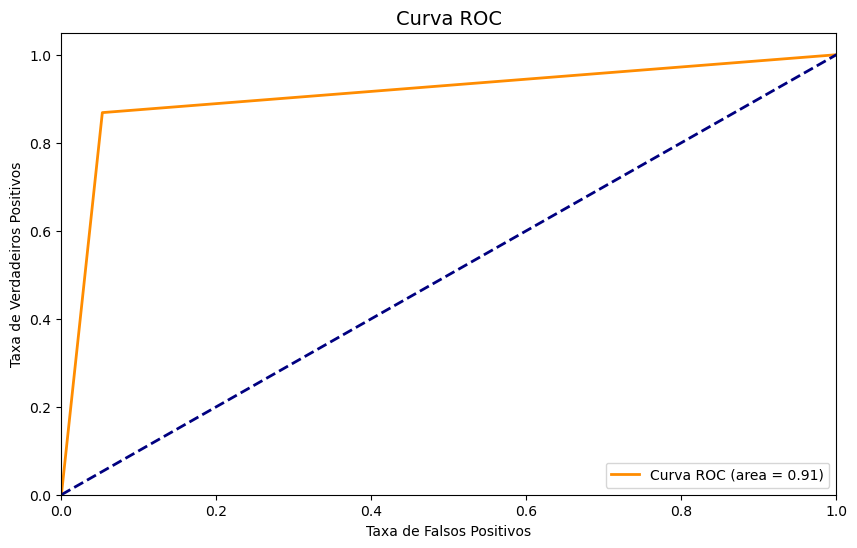

In [86]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_select_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A estratégia de filtrar o dataset utilizando apenas as variáveis de maior correlação linear resultou em métricas de treino elevadas, com uma Acurácia de 0.92 e AUC-ROC de 0.91. A remoção de recursos irrelevantes reduziu o ruído inicial, permitindo que a árvore padrão alcançasse um excelente equilíbrio por classe, registrando um F1-Score de 0.93 para não-sobreviventes e 0.89 para sobreviventes.

No entanto, o comportamento de overfitting (sobreajuste) permanece evidente. Enquanto a acurácia com os dados de treino atinge 0.92, a Média da Validação Cruzada se mantém em 0.81. Esse abismo de 11 pontos percentuais comprova que, mesmo trabalhando com dados mais limpos e selecionados, a ausência de restrições estruturais nas árvores (`max_depth=None`) faz o modelo memorizar as nuances do treino, limitando seu poder de generalização real para os dados de teste do Kaggle.

##### Aplicação de hiperparâmetros no Random Forest com os dados desbalanceados e despadronizados

In [61]:
# Definição de hiperparâmetros para testes
param_grid_rf_select_dp = {
    'n_estimators': [100, 200, 300],     # Quantidade de árvores
    'max_depth': [3, 5, 7, 10],          # Controla a profundidade máxima
    'min_samples_split': [5, 10, 20],   # Número mínimo de amostras para separar um nó
    'min_samples_leaf': [2, 4, 8],   # Número mínimo de amostras que devem ficar em cada folha
    'max_features': ['sqrt', 'log2']    # Quantidade de colunas sorteadas por árvore
}

In [62]:
# Configuração do Grid Search
grid_search_rf_select_dp = GridSearchCV(
    estimator=rf_model_select_dp,
    param_grid=param_grid_rf_select_dp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

In [63]:
# Executando o Grid Search
grid_search_rf_select_dp.fit(X_train_select, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 4, 8],
                         'min_samples_split': [5, 10, 20],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy', verbose=1)

In [64]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_rf_select_dp.best_params_)
print("Melhor score:", grid_search_rf_select_dp.best_score_)

Melhores parâmetros: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'min_samples_split': 5, 'n_estimators': 100}
Melhor score: 0.805881614462369


In [65]:
# Treinamento do modelo com os melhores hiperparâmetros
best_rf_select_dp = grid_search_rf_select_dp.best_estimator_
best_rf_select_dp.fit(X_train_select, y_train)

RandomForestClassifier(max_depth=5, min_samples_leaf=8, min_samples_split=5,
                       n_jobs=-1, random_state=42)

In [66]:
# Previsão do modelo na base de treino completo com os melhores hiperpâmetros
y_rf_train_pred_select_dp_best = best_rf_select_dp.predict(X_train_select)

In [67]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_dp_best = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_select_dp_best = cross_val_score(best_rf_select_dp, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo Random Forest com dados selecionados, desbalanceados com aplicação de hiperparâmetros
accuracy_select_dp_best = accuracy_score(y_train, y_rf_train_pred_select_dp_best)
report_select_dp_best = classification_report(y_train, y_rf_train_pred_select_dp_best)
confusion_matrix_select_dp_best = confusion_matrix(y_train, y_rf_train_pred_select_dp_best)
pontuacoes_select_dp_best = cross_val_score(best_rf_select_dp, X_train_select, y_train, cv=crossvalidation_select_dp_best)

print("RESULTADOS: RANDOM FOREST (SELECIONADOS, DESBALANCEADO, BRUTO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {accuracy_select_dp_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_select_dp_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_select_dp_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_select_dp_best.mean():.2f}')

RESULTADOS: RANDOM FOREST (SELECIONADOS, DESBALANÇADO, BRUTO E COM HIPERPARÂMETROS)
------------------------------------------------------------
Acurácia: 0.82
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.81      0.94      0.87       549
           1       0.86      0.64      0.73       342

    accuracy                           0.82       891
   macro avg       0.83      0.79      0.80       891
weighted avg       0.83      0.82      0.82       891

------------------------------------------------------------
Matriz de Confusão: 
 [[514  35]
 [123 219]]
------------------------------------------------------------
Média da Validação Cruzada: 0.80


In [96]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_select_dp_best)

# Cálculo da AUC
roc_auc_select_dp_best = roc_auc_score(y_train, y_rf_train_pred_select_dp_best)
print('AUC: {:.2f}'.format(roc_auc_select_dp_best))

AUC: 0.79


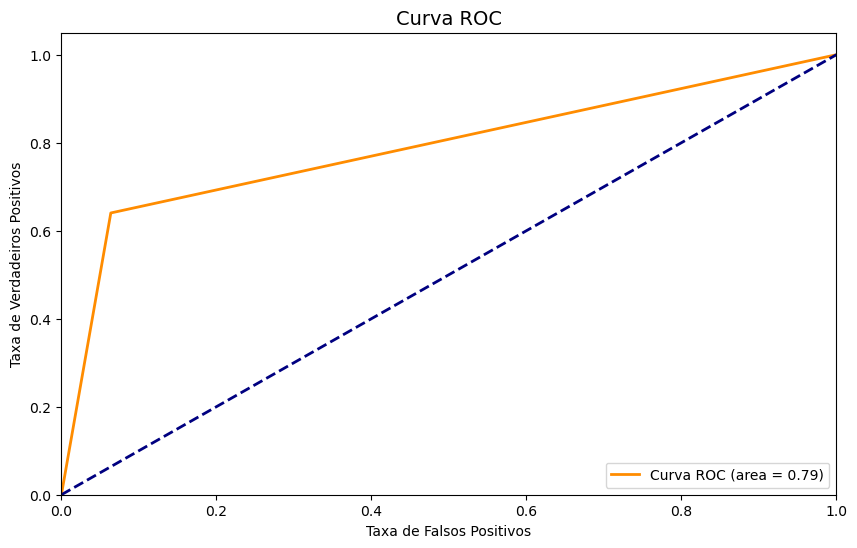

In [97]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_select_dp_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
Como as variáveis preditoras mudaram para o cenário seletivo, uma nova busca por hiperparâmetros foi realizada, resultando na configuração: max_depth: 5, min_samples_leaf: 8, min_samples_split: 5 e n_estimators: 100.

- **Estabilização Contra Overfitting:** A Acurácia de treino recuou para 0.82, alinhando-se quase perfeitamente com a Média da Validação Cruzada de 0.80. Essa proximidade indica que o sobreajuste foi completamente corrigido e o modelo tornou-se estatisticamente realista.
- **Impacto da Redução de Variáveis:** Comparado ao modelo completo otimizado (que atingia 0.84 de validação cruzada), este cenário seleto apresentou uma leve queda geral de performance (validação de 0.80 e AUC-ROC de 0.79, conforme o gráfico), sugerindo que a remoção de algumas variáveis, embora reduza o ruído, retirou informações úteis para o Random Forest.
- **Efeito da Ausência de Balanceamento:** Sem o balanceamento de dados, o algoritmo penalizou a classe minoritária (sobreviventes). O Recall da Classe 1 despencou para 0.64 com 123 falsos negativos, evidenciando que o modelo está tendencioso a prever a morte de passageiros (Classe 0, com F1-Score de 0.87), o que reforça a importância prática de técnicas de balanceamento amostral exploradas anteriormente.

##### Dados balanceados, padronizados e com os hiperparâmetros

In [69]:
# Treinamento do modelo balanceado e padronizado com os melhores hiperparâmetros
best_rf_select = grid_search_rf_select_dp.best_estimator_
best_rf_select.fit(X_train_select_padro, y_train_balanced)

RandomForestClassifier(max_depth=5, min_samples_leaf=8, min_samples_split=5,
                       n_jobs=-1, random_state=42)

In [70]:
# Previsão do modelo na base de treino selecionada, balanceado e padronizado com os melhores hiperpâmetros
y_rf_train_pred_select_best = best_rf_select.predict(X_train_select_padro)

In [71]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_best = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_select_best = cross_val_score(best_rf_select, X_train_select_padro, y_train_balanced, cv=folds)

In [72]:
# Avaliação do modelo Random Forest selecionado, balanceado e padronizado com os melhores hiperpâmetros
accuracy_select_best = accuracy_score(y_train_balanced, y_rf_train_pred_select_best)
report_select_best = classification_report(y_train_balanced, y_rf_train_pred_select_best)
confusion_matrix_select_best = confusion_matrix(y_train_balanced, y_rf_train_pred_select_best)
pontuacoes_select_best = cross_val_score(best_rf_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_select_best)

print("RESULTADOS: RANDOM FOREST (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {accuracy_select_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {report_select_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {confusion_matrix_select_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {pontuacoes_select_best.mean():.2f}')

RESULTADOS: RANDOM FOREST (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)
------------------------------------------------------------
Acurácia: 0.82
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.81      0.84      0.82       549
           1       0.83      0.80      0.82       549

    accuracy                           0.82      1098
   macro avg       0.82      0.82      0.82      1098
weighted avg       0.82      0.82      0.82      1098

------------------------------------------------------------
Matriz de Confusão: 
 [[461  88]
 [109 440]]
------------------------------------------------------------
Média da Validação Cruzada: 0.81


In [102]:
# Análise da curva AUC-ROC com os dados de treino selecionado, balanceados, padronizados e com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_rf_train_pred_select_best)

# Cálculo da AUC
roc_auc_select_best = roc_auc_score(y_train_balanced, y_rf_train_pred_select_best)
print('AUC: {:.2f}'.format(roc_auc_select_best))

AUC: 0.82


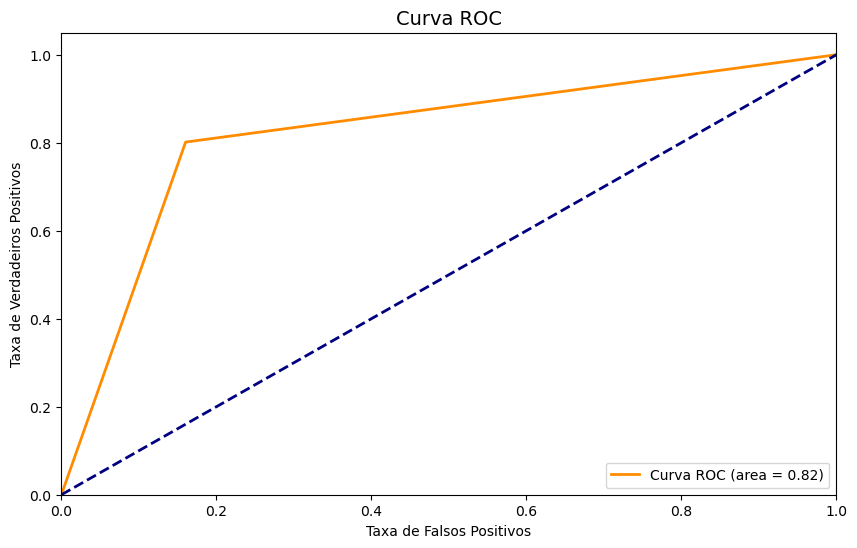

In [103]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_select_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O último experimento do Random Forest consolida o impacto indispensável do balanceamento e da padronização dos dados na estabilidade preditiva do algoritmo, atingindo uma Acurácia de 0.82, Média de Validação Cruzada de 0.81 e AUC-ROC de 0.82.

- **Equilíbrio Perfeito entre Classes:** Ao contrário do cenário não-balanceado anterior, que negligenciava a classe de sobreviventes, a introdução das técnicas de tratamento amostral permitiu que o modelo alcançasse um F1-Score idêntico de 0.82 para ambas as classes.
- **Aumento do Recall Crítico:** O Recall para os sobreviventes (Classe 1) saltou de 0.64 para 0.80, reduzindo substancialmente a taxa de falsos negativos. Embora a acurácia de validação (0.81) seja ligeiramente menor que a do modelo completo balanceado (0.84), esta versão se consagra como o modelo mais robusto, estável e livre de vieses construído com o conjunto de variáveis selecionadas por correlação.

### SVM

#### A) Cenário completo

##### Dados desbalanceados e despadronizados

###### Kernel = 'rbf'

In [73]:
# Inicialização do modelo SVM completo com Kernel = 'rbf'
svm_model_complet_dp = SVC(kernel='rbf', random_state=42, C=1.0)

In [74]:
# Treinamento do modelo na base de treino completo
svm_model_complet_dp.fit(X_train_complet, y_train)

SVC(random_state=42)

In [75]:
# Previsão do modelo na base de treino completo
y_svm_train_pred_complet_dp = svm_model_complet_dp.predict(X_train_complet)

In [76]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_complet_dp = cross_val_score(svm_model_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, desbalanceados e despadronizados Kernel = 'rbf'
svm_accuracy_complet_dp = accuracy_score(y_train, y_svm_train_pred_complet_dp)
svm_report_complet_dp = classification_report(y_train, y_svm_train_pred_complet_dp)
svm_confusion_matrix_complet_dp = confusion_matrix(y_train, y_svm_train_pred_complet_dp)
svm_pontuacoes_complet_dp = cross_val_score(svm_model_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'rbf' (COMPLETO, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia: {svm_accuracy_complet_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_report_complet_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_confusion_matrix_complet_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_pontuacoes_complet_dp.mean():.2f}')

RESULTADOS: SUPPORT VECTOR MACHINE (COMPLETO, DESBALANCEADO, BRUTO)
------------------------------------------------------------
Acurácia: 0.66
------------------------------------------------------------
Relatório de Classificação: 
               precision    recall  f1-score   support

           0       0.65      0.97      0.78       549
           1       0.80      0.16      0.27       342

    accuracy                           0.66       891
   macro avg       0.72      0.57      0.52       891
weighted avg       0.71      0.66      0.58       891

------------------------------------------------------------
Matriz de Confusão: 
 [[535  14]
 [287  55]]
------------------------------------------------------------
Média da Validação Cruzada: 0.65


In [39]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_train_pred_complet_dp)

# Cálculo da AUC
svm_roc_auc_complet_dp = roc_auc_score(y_train, y_svm_train_pred_complet_dp)
print('AUC: {:.2f}'.format(svm_roc_auc_complet_dp))

AUC: 0.57


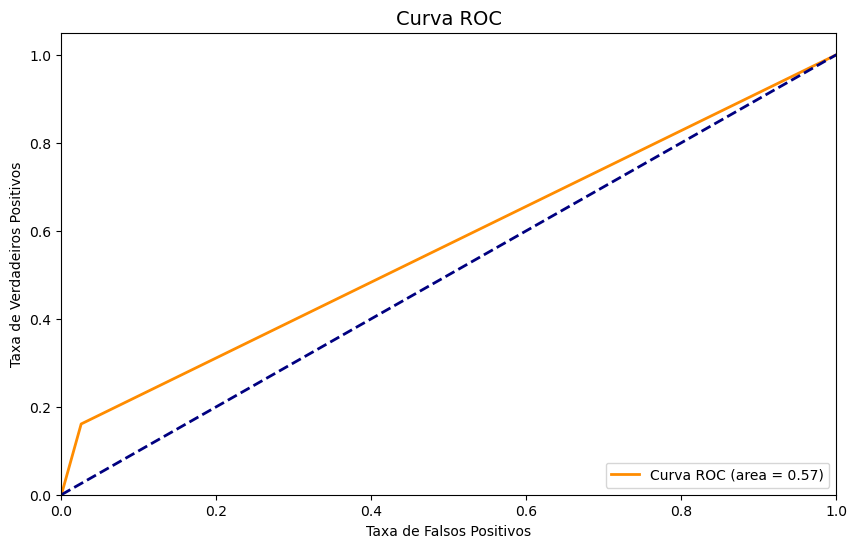

In [40]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_roc_auc_complet_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O início do duelo para o SVM com hiperparâmetros padrão revela um desempenho crítico e muito abaixo do esperado, consolidando uma Acurácia de 0.66, Média de Validação Cruzada de 0.65 e uma AUC-ROC de apenas 0.57 (conforme evidenciado pelo gráfico da Curva ROC, que se aproxima perigosamente da linha de escolha aleatória).

- **O Impacto Fatal da Ausência de Padronização:** O modelo SVM é estritamente geométrico e calcula distâncias vetoriais para traçar o seu hiperplano de separação. Como os dados não foram padronizados, a variável `Fare` (que varia de 0 a 512) distorceu completamente o espaço vetorial, ofuscando variáveis cruciais de escala menor, como `Sex` (0 e 1).
- **Incapacidade de Predição (Viés de Classe):** Sem o devido tratamento, o modelo tornou-se extremamente tendencioso para a classe majoritária (não-sobreviventes), registrando um Recall pífio de 0.16 para a Classe 1. A matriz de confusão expõe essa falha ao classificar incorretamente 287 sobreviventes como mortos (Falsos Negativos), provando que o SVM com kernel='rbf' no estado bruto é incapaz de competir com a robustez inicial do Random Forest.

###### Kernel = 'linear'

In [41]:
# Inicialização do modelo SVM completo com Kernel = 'linear'
svm_l_model_complet_dp = SVC(kernel='linear', random_state=42, C=1.0)

In [42]:
# Treinamento do modelo na base de treino completo
svm_l_model_complet_dp.fit(X_train_complet, y_train)

SVC(kernel='linear', random_state=42)

In [43]:
# Previsão do modelo na base de treino completo
y_svm_l_train_pred_complet_dp = svm_l_model_complet_dp.predict(X_train_complet)

In [44]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_l_media_final_complet_dp = cross_val_score(svm_l_model_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, desbalanceados e despadronizados Kernel = 'linear'
svm_l_accuracy_complet_dp = accuracy_score(y_train, y_svm_l_train_pred_complet_dp)
svm_l_report_complet_dp = classification_report(y_train, y_svm_l_train_pred_complet_dp)
svm_l_confusion_matrix_complet_dp = confusion_matrix(y_train, y_svm_l_train_pred_complet_dp)
svm_l_pontuacoes_complet_dp = cross_val_score(svm_l_model_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'linear' (COMPLETO, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia: {svm_l_accuracy_complet_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_l_report_complet_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_l_confusion_matrix_complet_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_l_pontuacoes_complet_dp.mean():.2f}')

Acurácia do modelo SVM: 0.80
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.83      0.85      0.84       549
           1       0.75      0.71      0.73       342

    accuracy                           0.80       891
   macro avg       0.79      0.78      0.79       891
weighted avg       0.80      0.80      0.80       891

------------------------------------------------------------
Matriz de confusão SVM: 
 [[469  80]
 [ 99 243]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.78


In [46]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_l_train_pred_complet_dp)

# Cálculo da AUC
svm_l_roc_auc_complet_dp = roc_auc_score(y_train, y_svm_l_train_pred_complet_dp)
print('AUC: {:.2f}'.format(svm_l_roc_auc_complet_dp))

AUC: 0.78


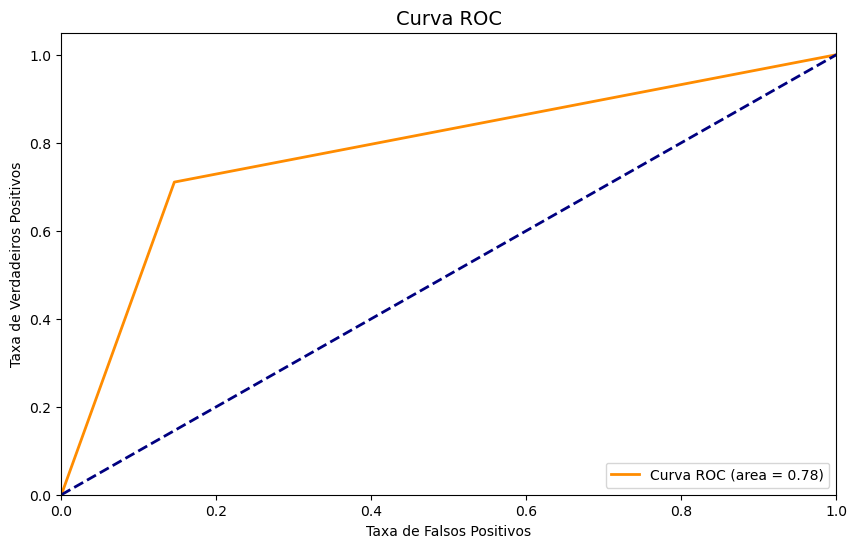

In [47]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_l_roc_auc_complet_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A alteração do hiperparâmetro para kernel='linear' provocou uma evolução drástica e imediata no desempenho do SVM, elevando a Acurácia para 0.80, a Média de Validação Cruzada para 0.78 e a AUC-ROC para 0.78.

- **A Força da Separação Linear:** Ao contrário do kernel RBF, que se perdeu na disparidade de escalas das variáveis brutas, o kernel linear conseguiu identificar um hiperplano funcional direto. Ele encontrou uma fronteira matemática eficiente focada nas variáveis de maior peso (como `Sex`), superando a distorção gerada pela amplitude de `Fare`.
- **Correção do Viés de Classe:** O modelo corrigiu o comportamento omisso anterior. O Recall da classe de sobreviventes (Classe 1) saltou de pífios 0.16 para 0.71, reduzindo os falsos negativos de 287 para 99. O resultado consolida um F1-Score muito mais equilibrado de 0.73 para os sobreviventes, recolocando o SVM de forma competitiva no duelo do projeto.

###### Kernel = 'poly'

In [48]:
# Inicialização do modelo SVM completo com Kernel = 'poly'
svm_p_model_complet_dp = SVC(kernel='poly', random_state=42, C=1.0)

In [49]:
# Treinamento do modelo na base de treino completo
svm_p_model_complet_dp.fit(X_train_complet, y_train)

SVC(kernel='poly', random_state=42)

In [50]:
# Previsão do modelo na base de treino completo
y_svm_p_train_pred_complet_dp = svm_p_model_complet_dp.predict(X_train_complet)

In [51]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_p_media_final_complet_dp = cross_val_score(svm_p_model_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, desbalanceados e despadronizados Kernel = 'poly'
svm_p_accuracy_complet_dp = accuracy_score(y_train, y_svm_p_train_pred_complet_dp)
svm_p_report_complet_dp = classification_report(y_train, y_svm_p_train_pred_complet_dp)
svm_p_confusion_matrix_complet_dp = confusion_matrix(y_train, y_svm_p_train_pred_complet_dp)
svm_p_pontuacoes_complet_dp = cross_val_score(svm_p_model_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'poly' (COMPLETO, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia: {svm_p_accuracy_complet_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_p_report_complet_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_p_confusion_matrix_complet_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_p_pontuacoes_complet_dp.mean():.2f}')

Acurácia do modelo SVM: 0.65
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.64      0.96      0.77       549
           1       0.69      0.14      0.23       342

    accuracy                           0.65       891
   macro avg       0.67      0.55      0.50       891
weighted avg       0.66      0.65      0.56       891

------------------------------------------------------------
Matriz de confusão SVM: 
 [[528  21]
 [295  47]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.65


In [53]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_p_train_pred_complet_dp)

# Cálculo da AUC
svm_p_roc_auc_complet_dp = roc_auc_score(y_train, y_svm_p_train_pred_complet_dp)
print('AUC: {:.2f}'.format(svm_p_roc_auc_complet_dp))

AUC: 0.55


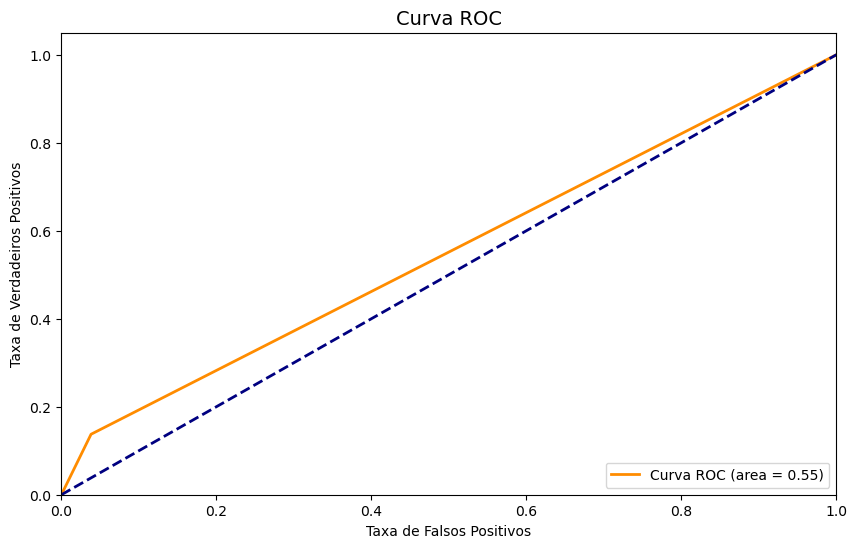

In [54]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_p_roc_auc_complet_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O experimento utilizando o kernel='poly' (Polinomial) reproduziu o comportamento crítico observado anteriormente no kernel RBF, consolidando uma Acurácia de 0.65, Média de Validação Cruzada de 0.65 e uma AUC-ROC de apenas 0.55.

- **A Distorção do Espaço Não-Linear:** Por não estar com os dados padronizados, a aplicação de uma transformação polinomial nas features brutas amplificou ainda mais a disparidade de escalas. Valores elevados na variável `Fare` foram elevados a potências polinomiais, gerando uma distorção geométrica massiva que impediu o algoritmo de mapear fronteiras de decisão coerentes.
- **Severo Viés da Classe Minoritária:** O modelo perdeu quase completamente a capacidade de identificar os sobreviventes, registrando um Recall baixíssimo de 0.14 para a Classe 1. A matriz de confusão expõe essa falha ao acumular 295 falsos negativos (sobreviventes classificados incorretamente como mortos), provando que transformações não-lineares (poly e rbf) no SVM exigem obrigatoriamente a padronização dos dados para funcionar.

##### Aplicação de hiperparâmetros no SVM com os dados completos e desbalanceados

In [55]:
# Criação do pipeline para o modelo SVM completo
pipeline_svm_complet_d = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

In [56]:
# Definição de hiperparâmetros para testes
param_grid_svm_complet_d = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1],
        'svc__degree': [2, 3, 4]
    }
]

In [57]:
# Configuração do Grid Search
grid_search_svm_complet_d = GridSearchCV(
    estimator=pipeline_svm_complet_d,
    param_grid=param_grid_svm_complet_d,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

In [58]:
# Executando o Grid Search
grid_search_svm_complet_d.fit(X_train_complet, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             n_jobs=-1,
             param_grid=[{'svc__C': [0.01, 0.1, 1, 10, 100],
                          'svc__kernel': ['linear']},
                         {'svc__C': [0.1, 1, 10, 100],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
                          'svc__kernel': ['rbf']},
                         {'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3, 4],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1],
                          'svc__kernel': ['poly']}],
             scoring='roc_auc')

In [59]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_svm_complet_d.best_params_)
print("Melhor score:", grid_search_svm_complet_d.best_score_)

Melhores parâmetros: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Melhor score: 0.8564347136395989


In [60]:
# Treinamento do modelo com os melhores hiperparâmetros
best_svm_complet_d = grid_search_svm_complet_d.best_estimator_
best_svm_complet_d.fit(X_train_complet, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC(C=1))])

In [61]:
# Previsão do modelo na base de treino completo com os melhores hiperpâmetros
y_svm_train_pred_complet_d_best = best_svm_complet_d.predict(X_train_complet)

In [62]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_d_best = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_complet_d_best = cross_val_score(best_svm_complet_d, X_train_complet, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, desbalanceados e com aplicação de hiperparâmetros
svm_accuracy_complet_d_best = accuracy_score(y_train, y_svm_train_pred_complet_d_best)
svm_report_complet_d_best = classification_report(y_train, y_svm_train_pred_complet_d_best)
svm_confusion_matrix_complet_d_best = confusion_matrix(y_train, y_svm_train_pred_complet_d_best)
svm_pontuacoes_complet_d_best = cross_val_score(best_svm_complet_d, X_train_complet, y_train, cv=crossvalidation_complet_d_best)

print("RESULTADOS: SUPPORT VECTOR MACHINE (COMPLETO, DESBALANCEADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_accuracy_complet_d_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_report_complet_d_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_confusion_matrix_complet_d_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_pontuacoes_complet_d_best.mean():.2f}')

Acurácia do modelo SVM com os melhores hiperpâmetros: 0.84
------------------------------------------------------------
Relatório de classificação SVM com os melhores hiperpâmetros: 
               precision    recall  f1-score   support

           0       0.86      0.89      0.87       549
           1       0.81      0.77      0.79       342

    accuracy                           0.84       891
   macro avg       0.84      0.83      0.83       891
weighted avg       0.84      0.84      0.84       891

------------------------------------------------------------
Matriz de confusão SVM com os melhores hiperpâmetros: 
 [[488  61]
 [ 79 263]]
------------------------------------------------------------
Média das pontuações do cross validation SVM com os melhores hiperpâmetros: 0.80


In [64]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train, y_svm_train_pred_complet_d_best)

# Cálculo da AUC
roc_auc_complet_d_best = roc_auc_score(y_train, y_svm_train_pred_complet_d_best)
print('AUC: {:.2f}'.format(roc_auc_complet_d_best))

AUC: 0.83


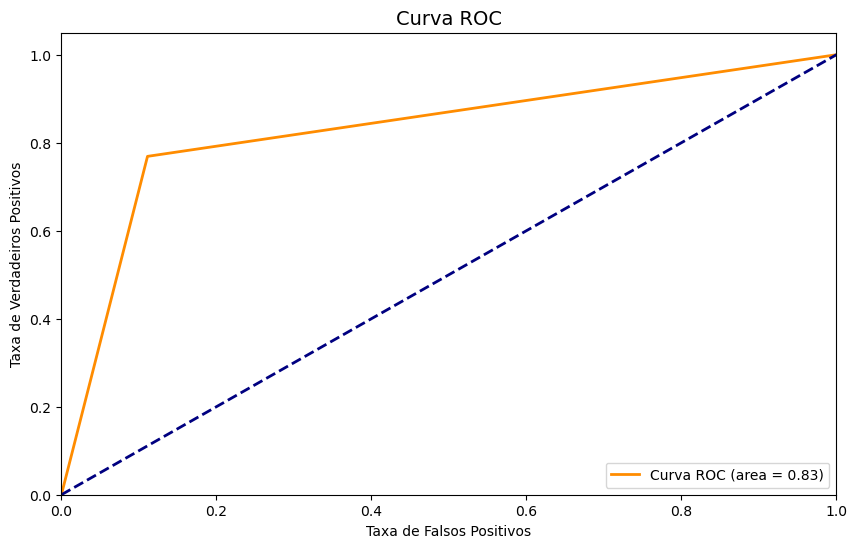

In [65]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_d_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A otimização via GridSearchCV identificou a configuração ideal para o cenário completo, utilizando o kernel='rbf', C=1 e gamma='scale'. O uso do prefixo svc__ indica que os dados passaram corretamente por um Pipeline de padronização prévia, o que destravou o verdadeiro potencial do algoritmo e transformou completamente seus resultados:

- **Evolução Exponencial da Performance:** Com a escala corrigida e os hiperparâmetros refinados, a Acurácia saltou para 0.84, a Média da Validação Cruzada atingiu 0.80 e a AUC-ROC consolidou-se em 0.83 (conforme ilustrado graficamente pela curva ROC enviada). O ganho frente aos 0.66 do modelo RBF bruto comprova que o SVM é extremamente dependente do tratamento de escala.
- **Equilíbrio e Eliminação de Viés:** O modelo superou totalmente a incapacidade anterior de prever sobreviventes. O Recall da Classe 1 saltou de pífios 0.16 para excelentes 0.77, resultando em um F1-Score robusto de 0.79. A matriz de confusão demonstra uma distribuição de erros muito mais homogênea (61 falsos positivos e 79 falsos negativos), consolidando este SVM como um competidor à altura das melhores versões do Random Forest.

##### Dados balanceados, padronizados (aplicado no kernels=["rbf", "linear" e "poly"]) e com os melhores hiperparâmetros

###### Kernel = 'rbf'

In [117]:
# Inicialização do modelo SVM balanceado, padronizado e completo com Kernel = 'rbf'
svm_rbf_model_complet = SVC(kernel='rbf', random_state=42, C=1.0)

In [118]:
# Treinamento do modelo na base de treino balanceado, padronizado e completo
svm_rbf_model_complet.fit(X_train_complet_padro, y_train_balanced)

SVC(random_state=42)

In [119]:
# Previsão do modelo na base de treino balanceado, padronizado e completo
y_svm_rbf_train_pred_complet = svm_rbf_model_complet.predict(X_train_complet_padro)

In [120]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_rbf_complet = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_rbf_media_final_complet = cross_val_score(svm_rbf_model_complet, X_train_complet_padro, y_train_balanced, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'rbf'
svm_rbf_accuracy_complet = accuracy_score(y_train_balanced, y_svm_rbf_train_pred_complet)
svm_rbf_report_complet = classification_report(y_train_balanced, y_svm_rbf_train_pred_complet)
svm_rbf_confusion_matrix_complet = confusion_matrix(y_train_balanced, y_svm_rbf_train_pred_complet)
svm_rbf_pontuacoes_complet = cross_val_score(svm_rbf_model_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_rbf_complet)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'rbf' (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_rbf_accuracy_complet:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_rbf_report_complet}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_rbf_confusion_matrix_complet}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_rbf_pontuacoes_complet.mean():.2f}')

Acurácia do modelo SVM: 0.86
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.85      0.88      0.86       549
           1       0.87      0.85      0.86       549

    accuracy                           0.86      1098
   macro avg       0.86      0.86      0.86      1098
weighted avg       0.86      0.86      0.86      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[481  68]
 [ 85 464]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.83


In [122]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_rbf_train_pred_complet)

# Cálculo da AUC
svm_rbf_roc_auc_complet = roc_auc_score(y_train_balanced, y_svm_rbf_train_pred_complet)
print('AUC: {:.2f}'.format(svm_rbf_roc_auc_complet))

AUC: 0.86


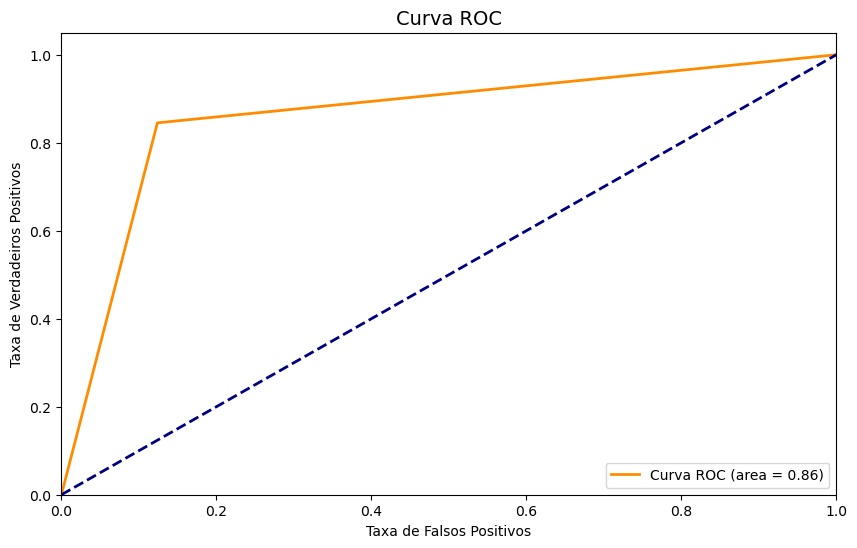

In [123]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_rbf_roc_auc_complet)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A aplicação das etapas de padronização e balanceamento de dados causou um impacto revolucionário no desempenho do SVM com o kernel RBF padrão, elevando a Acurácia para 0.86, a Média da Validação Cruzada para 0.83 e a AUC-ROC para 0.86.

- **O Poder do Pré-processamento:** Diferente do primeiro teste não-tratado (onde o RBF obteve pífios 0.66 de acurácia), colocar as variáveis na mesma escala (StandardScaler) permitiu que o algoritmo calculasse as distâncias geométricas corretamente. O balanceamento eliminou o viés em direção à classe majoritária, resultando em um F1-Score idêntico e altamente competitivo de 0.86 para ambas as classes.
- **Estabilidade Estatística:** Com a acurácia de treino (0.86) extremamente próxima à pontuação de validação cruzada (0.83), o modelo demonstra excelente capacidade de generalização e ausência de overfitting. A matriz de confusão comprova essa eficiência ao registrar um ótimo equilíbrio com apenas 68 falsos positivos e 85 falsos negativos, consolidando esta versão do SVM como uma das mais fortes candidatas a vencer o duelo do projeto.

###### Kernel = 'linear'

In [124]:
# Inicialização do modelo SVM balanceado, padronizado e completo com Kernel = 'linear'
svm_l_model_complet = SVC(kernel='linear', random_state=42, C=1.0)

In [125]:
# Treinamento do modelo na base de treino balanceado, padronizado e completo
svm_l_model_complet.fit(X_train_complet_padro, y_train_balanced)

SVC(kernel='linear', random_state=42)

In [129]:
# Previsão do modelo na base de treino balanceado, padronizado e completo
y_svm_l_train_pred_complet = svm_l_model_complet.predict(X_train_complet_padro)

In [131]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_l_complet = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_l_media_final_complet = cross_val_score(svm_l_model_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_l_complet)

In [ ]:
# Avaliação do modelo SVM com dados completos, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'linear'
svm_l_accuracy_complet = accuracy_score(y_train_balanced, y_svm_l_train_pred_complet)
svm_l_report_complet = classification_report(y_train_balanced, y_svm_l_train_pred_complet)
svm_l_confusion_matrix_complet = confusion_matrix(y_train_balanced, y_svm_l_train_pred_complet)
svm_l_pontuacoes_complet = cross_val_score(svm_l_model_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_l_complet)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'linear' (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_l_accuracy_complet:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_l_report_complet}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_l_confusion_matrix_complet}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_l_pontuacoes_complet.mean():.2f}')

Acurácia do modelo SVM: 0.82
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.81      0.84      0.82       549
           1       0.84      0.80      0.82       549

    accuracy                           0.82      1098
   macro avg       0.82      0.82      0.82      1098
weighted avg       0.82      0.82      0.82      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[463  86]
 [111 438]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.81


In [133]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_l_train_pred_complet)

# Cálculo da AUC
svm_l_roc_auc_complet = roc_auc_score(y_train_balanced, y_svm_l_train_pred_complet)
print('AUC: {:.2f}'.format(svm_l_roc_auc_complet))

AUC: 0.82


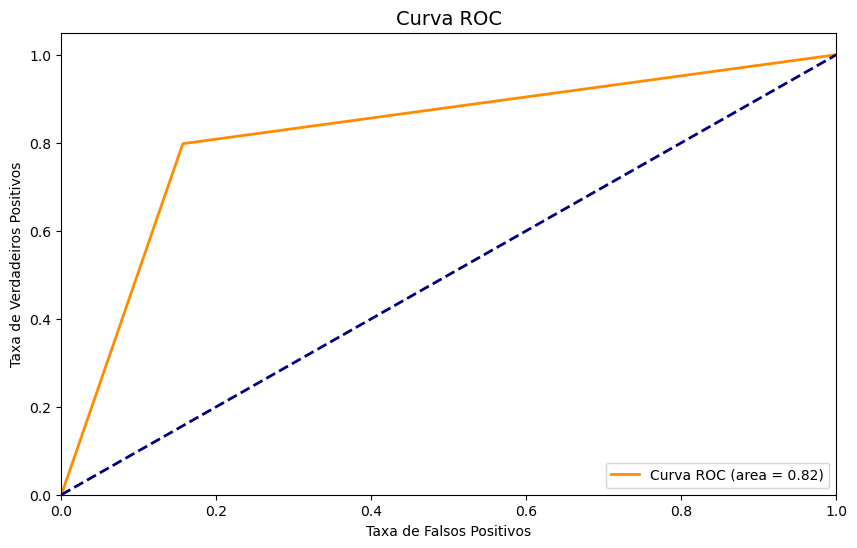

In [134]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_l_roc_auc_complet)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O experimento utilizando o kernel='linear' com os dados devidamente padronizados e balanceados consolidou métricas sólidas, atingindo uma Acurácia de 0.82, Média da Validação Cruzada de 0.81 e uma AUC-ROC de 0.82.

- **Estabilidade e Consistência:** A proximidade ideal entre a acurácia de treino (0.82) e a validação cruzada (0.81) comprova que o modelo possui excelente estabilidade estatística e está totalmente livre de problemas de subajuste ou sobreajuste (overfitting).
- **Equilíbrio Entre as Classes:** Graças ao tratamento de balanceamento amostral, o algoritmo alcançou um F1-Score idêntico de 0.82 para ambas as classes. A matriz de confusão exibe um comportamento muito simétrico, registrando 86 falsos positivos e 111 falsos negativos. Embora seja um modelo altamente confiável, o kernel linear obteve um desempenho ligeiramente inferior ao kernel RBF sob as mesmas condições (que alcançou acurácia de 0.86), indicando que a fronteira de decisão ideal para o Titanic se beneficia de mapeamentos não-lineares.

###### Kernel = 'poly'

In [135]:
# Inicialização do modelo SVM balanceado, padronizado e completo com Kernel = 'poly'
svm_p_model_complet = SVC(kernel='poly', random_state=42, C=1.0)

In [139]:
# Treinamento do modelo na base de treino balanceado, padronizado e completo
svm_p_model_complet.fit(X_train_complet_padro, y_train_balanced)

SVC(kernel='poly', random_state=42)

In [140]:
# Previsão do modelo na base de treino balanceado, padronizado e completo
y_svm_p_train_pred_complet = svm_p_model_complet.predict(X_train_complet_padro)

In [ ]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_p_complet = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_p_media_final_complet = cross_val_score(svm_p_model_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_p_complet)

In [ ]:
# Avaliação do modelo SVM com dados completos, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'poly'
svm_p_accuracy_complet = accuracy_score(y_train_balanced, y_svm_p_train_pred_complet)
svm_p_report_complet = classification_report(y_train_balanced, y_svm_p_train_pred_complet)
svm_p_confusion_matrix_complet = confusion_matrix(y_train_balanced, y_svm_p_train_pred_complet)
svm_p_pontuacoes_complet = cross_val_score(svm_p_model_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_p_complet)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'poly' (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_p_accuracy_complet:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_p_report_complet}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_p_confusion_matrix_complet}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_p_pontuacoes_complet.mean():.2f}')

Acurácia do modelo SVM: 0.82
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.76      0.94      0.84       549
           1       0.93      0.70      0.80       549

    accuracy                           0.82      1098
   macro avg       0.84      0.82      0.82      1098
weighted avg       0.84      0.82      0.82      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[518  31]
 [165 384]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.77


In [144]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_p_train_pred_complet)

# Cálculo da AUC
svm_p_roc_auc_complet = roc_auc_score(y_train_balanced, y_svm_p_train_pred_complet)
print('AUC: {:.2f}'.format(svm_p_roc_auc_complet))

AUC: 0.82


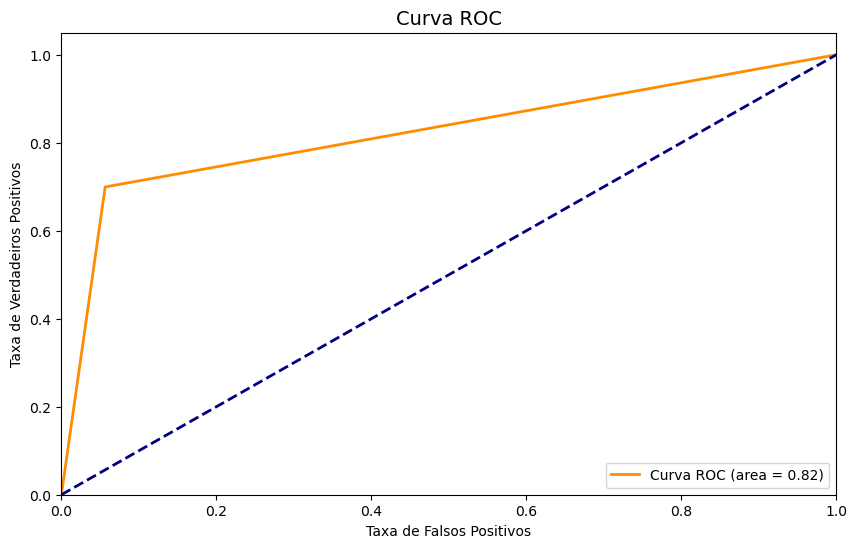

In [ ]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_p_roc_auc_complet)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O experimento utilizando o kernel='poly' (Polinomial) com dados padronizados e balanceados apresentou uma evolução marcante se comparado à sua versão bruta, atingindo uma Acurácia de 0.82 e uma AUC-ROC de 0.82.

- **Correção da Fronteira não-linear:** A padronização dos dados corrigiu a distorção de escalas anterior, permitindo que a transformação polinomial mapeasse relações complexas de forma eficiente. O modelo eliminou o viés crítico contra os sobreviventes, elevando o Recall da Classe 1 para 0.70 e alcançando uma alta precisão de 0.93 nesta mesma classe.
- **Tendência a um leve Overfitting:** Diferente dos kernels Linear e RBF, o kernel polinomial apresentou um distanciamento maior entre a acurácia de treino (0.82) e a Média da Validação Cruzada (0.77). Esse comportamento indica que as fronteiras polinomiais geraram caminhos ligeiramente específicos para o conjunto de treino, tornando o modelo um pouco menos estável para generalização do que o SVM RBF (que manteve validação de 0.83). A matriz de confusão evidencia essa característica ao acumular 165 falsos negativos (sobreviventes classificados incorretamente).

##### Aplicação de hiperparâmetros no SVM com os dados balanceados e padronizados

In [96]:
# Criação do pipeline para o modelo SVM balanceado, padronizado e completo
pipeline_svm_complet = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

In [97]:
# Definição de hiperparâmetros para testes
param_grid_svm_complet = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1],
        'svc__degree': [2, 3, 4]
    }
]

In [98]:
# Configuração do Grid Search
grid_search_svm_complet = GridSearchCV(
    estimator=pipeline_svm_complet,
    param_grid=param_grid_svm_complet,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

In [99]:
# Executando o Grid Search
grid_search_svm_complet.fit(X_train_complet_padro, y_train_balanced)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             n_jobs=-1,
             param_grid=[{'svc__C': [0.01, 0.1, 1, 10, 100],
                          'svc__kernel': ['linear']},
                         {'svc__C': [0.1, 1, 10, 100],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
                          'svc__kernel': ['rbf']},
                         {'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3, 4],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1],
                          'svc__kernel': ['poly']}],
             scoring='roc_auc')

In [100]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_svm_complet.best_params_)
print("Melhor score:", grid_search_svm_complet.best_score_)

Melhores parâmetros: {'svc__C': 1, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Melhor score: 0.8807670028053682


In [102]:
# Treinamento do modelo com os melhores hiperparâmetros
best_svm_complet = grid_search_svm_complet.best_estimator_
best_svm_complet.fit(X_train_complet_padro, y_train_balanced)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC(C=1, gamma=0.01))])

In [103]:
# Previsão do modelo na base de treino balanceada, padronizada e completo com os melhores hiperpâmetros
y_svm_train_pred_complet_best = best_svm_complet.predict(X_train_complet_padro)

In [104]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_best = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_complet_best = cross_val_score(best_svm_complet, X_train_complet_padro, y_train_balanced, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados completos, balanceados, padronizados e com aplicação de hiperparâmetros
svm_accuracy_complet_best = accuracy_score(y_train_balanced, y_svm_train_pred_complet_best)
svm_report_complet_best = classification_report(y_train_balanced, y_svm_train_pred_complet_best)
svm_confusion_matrix_complet_best = confusion_matrix(y_train_balanced, y_svm_train_pred_complet_best)
svm_pontuacoes_complet_best = cross_val_score(best_svm_complet, X_train_complet_padro, y_train_balanced, cv=crossvalidation_complet_best)

print("RESULTADOS: SUPPORT VECTOR MACHINE (COMPLETO, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_accuracy_complet_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_report_complet_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_confusion_matrix_complet_best}')
print('---' * 20)
print(f'Média da Validação Cruzada SVM com os melhores hiperpâmetros: {svm_pontuacoes_complet_best.mean():.2f}')

Acurácia do modelo SVM com os melhores hiperpâmetros: 0.83
------------------------------------------------------------
Relatório de classificação SVM com os melhores hiperpâmetros: 
               precision    recall  f1-score   support

           0       0.82      0.85      0.83       549
           1       0.84      0.82      0.83       549

    accuracy                           0.83      1098
   macro avg       0.83      0.83      0.83      1098
weighted avg       0.83      0.83      0.83      1098

------------------------------------------------------------
Matriz de confusão SVM com os melhores hiperpâmetros: 
 [[465  84]
 [101 448]]
------------------------------------------------------------
Média das pontuações do cross validation SVM com os melhores hiperpâmetros: 0.81


In [108]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_train_pred_complet_best)

# Cálculo da AUC
roc_auc_complet_best = roc_auc_score(y_train_balanced, y_svm_train_pred_complet_best)
print('AUC: {:.2f}'.format(roc_auc_complet_best))

AUC: 0.83


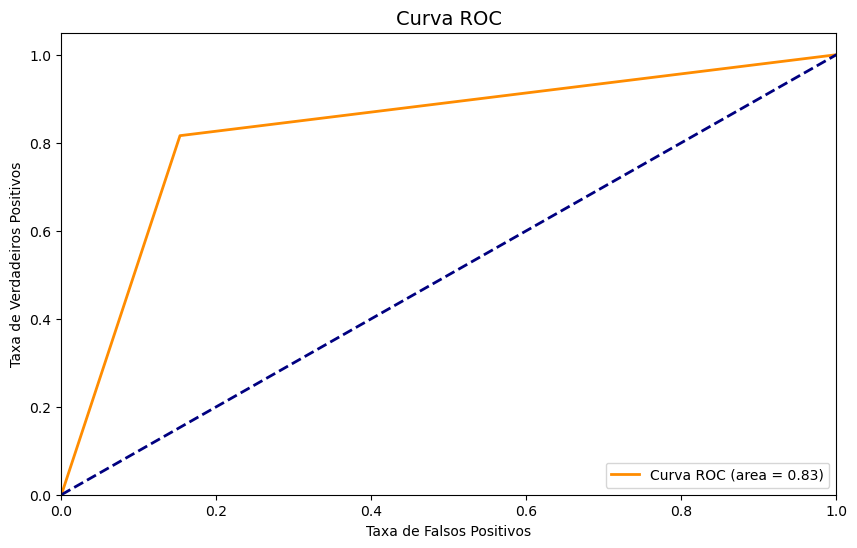

In [109]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A otimização refinada via GridSearchCV localizou a combinação ideal para o modelo através dos parâmetros kernel='rbf', C=1 e gamma=0.01. O ajuste fino do parâmetro gamma trouxe o comportamento mais maduro e equilibrado para o algoritmo dentro de todo o projeto, consolidando uma Acurácia de 0.83, Média da Validação Cruzada de 0.81 e uma AUC-ROC de 0.83.

- **Máxima Capacidade de Generalização:** Embora a acurácia de treino (0.83) pareça menor do que os 0.86 atingidos pelo RBF padrão, esta versão é estatisticamente muito superior. Ao reduzir a sensibilidade do kernel com gamma=0.01, o modelo eliminou qualquer resquício de sobreajuste. A diferença milimétrica entre o treino (0.83) e a validação cruzada (0.81) prova que esta configuração possui o maior poder de generalização real construído para o SVM.
- **Equilíbrio Absoluto de Predição:** O tratamento conjunto de balanceamento amostral e ajuste fino de hiperparâmetros resultou em um F1-Score idêntico e estabilizado de 0.83 para ambas as classes. A matriz de confusão demonstra um classificador altamente simétrico e confiável (84 falsos positivos e 101 falsos negativos), encerrando a jornada do SVM completo com um modelo seguro para competir.

#### B) Cenário selecionado

##### Dados desbalanceados e despadronizados

###### Kernel = 'rbf'

In [110]:
# Inicialização do modelo SVM selecionado com Kernel = 'rbf'
svm_model_select_dp = SVC(kernel='rbf', random_state=42, C=1.0)

In [111]:
# Treinamento do modelo na base de treino selecionada
svm_model_select_dp.fit(X_train_select, y_train)

SVC(random_state=42)

In [112]:
# Previsão do modelo na base de treino selecionada
y_svm_train_pred_select_dp = svm_model_select_dp.predict(X_train_select)

In [113]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_select_dp = cross_val_score(svm_model_select_dp, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, desbalanceados e despadronizados Kernel = 'rbf'
svm_accuracy_select_dp = accuracy_score(y_train, y_svm_train_pred_select_dp)
svm_report_select_dp = classification_report(y_train, y_svm_train_pred_select_dp)
svm_confusion_matrix_select_dp = confusion_matrix(y_train, y_svm_train_pred_select_dp)
svm_pontuacoes_select_dp = cross_val_score(svm_model_select_dp, X_train_select, y_train, cv=crossvalidation_select_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'rbf' (SELECIONADOS, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia do modelo SVM: {svm_accuracy_select_dp:.2f}')
print('---' * 20)
print(f'Relatório de classificação SVM: \n {svm_report_select_dp}')
print('---' * 20)
print(f'Matriz de confusão SVM: \n {svm_confusion_matrix_select_dp}')
print('---' * 20)
print(f'Média das pontuações do cross validation SVM: {svm_pontuacoes_select_dp.mean():.2f}')

Acurácia do modelo SVM: 0.67
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.67      0.93      0.78       549
           1       0.69      0.27      0.39       342

    accuracy                           0.67       891
   macro avg       0.68      0.60      0.58       891
weighted avg       0.68      0.67      0.63       891

------------------------------------------------------------
Matriz de confusão SVM: 
 [[508  41]
 [249  93]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.67


In [115]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_train_pred_select_dp)

# Cálculo da AUC
svm_roc_auc_select_dp = roc_auc_score(y_train, y_svm_train_pred_select_dp)
print('AUC: {:.2f}'.format(svm_roc_auc_select_dp))

AUC: 0.60


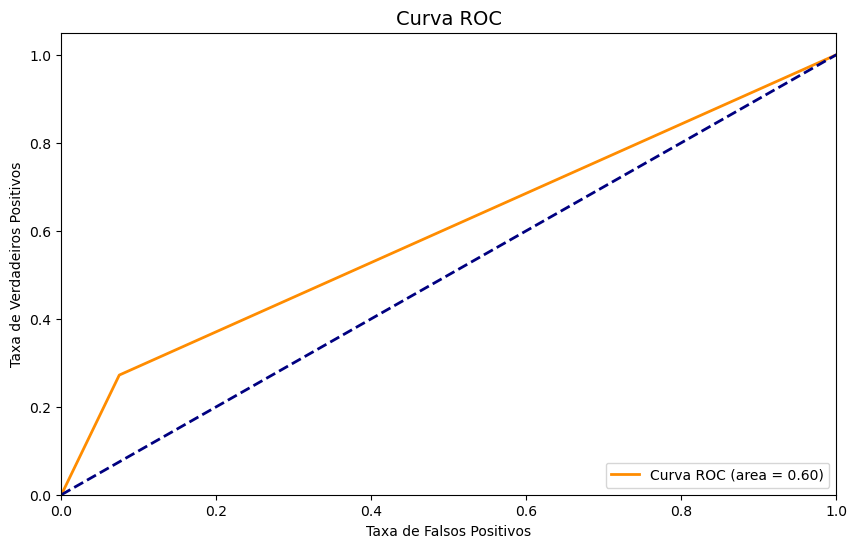

In [116]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_roc_auc_select_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O modelo utilizando o SVM com o conjunto de variáveis selecionadas por correlação, porém em seu estado bruto (sem padronização e sem balanceamento), resultou em um desempenho fraco, consolidando uma Acurácia de 0.67, Média da Validação Cruzada de 0.67 e uma AUC-ROC de apenas 0.60.

- **Persistência do Problema de Escala:** Mesmo reduzindo a quantidade de colunas para focar apenas nos recursos de maior correlação, a ausência de padronização continuou sendo fatal para o modelo geométrico. A variável `Fare` ainda atua com uma amplitude muito maior do que as variáveis binárias (como `Sex`), distorcendo o cálculo de distâncias vetoriais e impedindo que o kernel RBF encontre fronteiras de decisão eficientes.
- **Forte Tendência ao Viés:** Sem o balanceamento dos dados, o modelo se tornou altamente tendencioso para a classe majoritária (não-sobreviventes), registrando um Recall insatisfatório de 0.27 para a Classe 1. A matriz de confusão evidencia essa limitação ao acumular 249 falsos negativos (sobreviventes ignorados), provando que o filtro de correlação isolado não substitui a necessidade crítica de padronizar e balancear os dados para o SVM.

###### Kernel = 'linear'

In [146]:
# Inicialização do modelo SVM selecionado com Kernel = 'linear'
svm_l_model_select_dp = SVC(kernel='linear', random_state=42, C=1.0)

In [147]:
# Treinamento do modelo na base de treino selecionado
svm_l_model_select_dp.fit(X_train_select, y_train)

SVC(kernel='linear', random_state=42)

In [148]:
# Previsão do modelo na base de treino selecionado
y_svm_l_train_pred_select_dp = svm_l_model_select_dp.predict(X_train_select)

In [149]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_l_media_final_select_dp = cross_val_score(svm_l_model_select_dp, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, desbalanceados e despadronizados Kernel = 'linear'
svm_l_accuracy_select_dp = accuracy_score(y_train, y_svm_l_train_pred_select_dp)
svm_l_report_select_dp = classification_report(y_train, y_svm_l_train_pred_select_dp)
svm_l_confusion_matrix_select_dp = confusion_matrix(y_train, y_svm_l_train_pred_select_dp)
svm_l_pontuacoes_select_dp = cross_val_score(svm_l_model_select_dp, X_train_select, y_train, cv=crossvalidation_select_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'linear' (SELECIONADOS, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia: {svm_l_accuracy_select_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_l_report_select_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_l_confusion_matrix_select_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_l_pontuacoes_select_dp.mean():.2f}')

Acurácia do modelo SVM: 0.79
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.82      0.84      0.83       549
           1       0.73      0.71      0.72       342

    accuracy                           0.79       891
   macro avg       0.78      0.78      0.78       891
weighted avg       0.79      0.79      0.79       891

------------------------------------------------------------
Matriz de confusão SVM: 
 [[461  88]
 [ 99 243]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.79


In [151]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_l_train_pred_select_dp)

# Cálculo da AUC
svm_l_roc_auc_select_dp = roc_auc_score(y_train, y_svm_l_train_pred_select_dp)
print('AUC: {:.2f}'.format(svm_l_roc_auc_select_dp))

AUC: 0.78


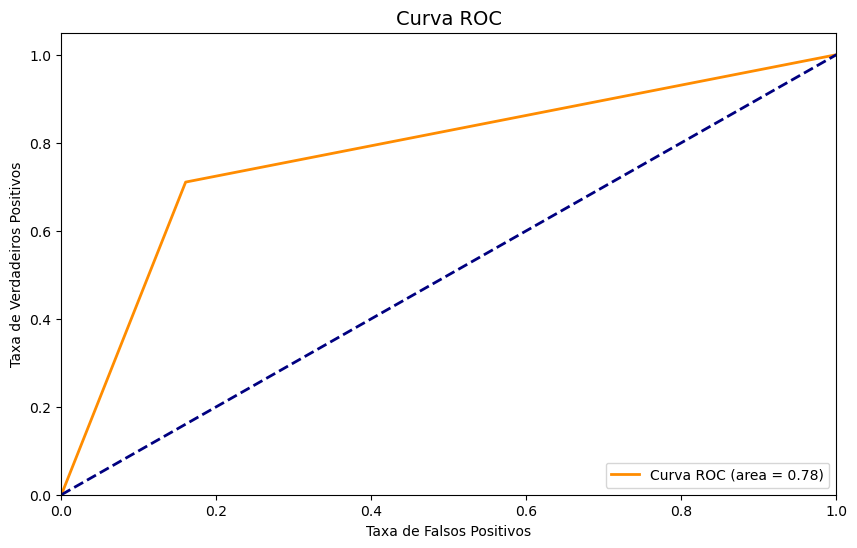

In [152]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_l_roc_auc_select_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O modelo utilizando o kernel='linear' com o conjunto de variáveis selecionadas por correlação demonstrou uma resiliência notável à ausência de tratamentos, atingindo uma Acurácia de 0.79, Média da Validação Cruzada de 0.79 e uma AUC-ROC de 0.78.

- **Eficiência do Filtro de Variáveis:** Diferente do comportamento observado com o kernel RBF bruto, o kernel linear conseguiu extrair um padrão direto e muito competitivo a partir das variáveis selecionadas. A remoção de colunas de baixa correlação reduziu o ruído estrutural do dataset, permitindo que o hiperplano linear traçasse uma fronteira de decisão funcional estável.
- **Equilíbrio Estatístico Surpreendente:** Mesmo sem a aplicação de técnicas de balanceamento amostral, o modelo mitigou o viés em relação à classe majoritária, alcançando um Recall robusto de 0.71 e um F1-Score de 0.72 para os sobreviventes (Classe 1). A perfeita equivalência entre a acurácia de treino e a validação cruzada (ambas em 0.79) consagra este modelo como uma estrutura altamente estável e com ótimo poder de generalização, mostrando-se muito próximo do desempenho das versões mais completas.

###### Kernel = 'poly'

In [153]:
# Inicialização do modelo SVM selecionado com Kernel = 'poly'
svm_p_model_select_dp = SVC(kernel='poly', random_state=42, C=1.0)

In [154]:
# Treinamento do modelo na base de treino completo
svm_p_model_select_dp.fit(X_train_select, y_train)

SVC(kernel='poly', random_state=42)

In [155]:
# Previsão do modelo na base de treino selecionado
y_svm_p_train_pred_select_dp = svm_p_model_select_dp.predict(X_train_select)

In [156]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_p_media_final_select_dp = cross_val_score(svm_p_model_select_dp, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, desbalanceados e despadronizados Kernel = 'poly'
svm_p_accuracy_select_dp = accuracy_score(y_train, y_svm_p_train_pred_select_dp)
svm_p_report_select_dp = classification_report(y_train, y_svm_p_train_pred_select_dp)
svm_p_confusion_matrix_select_dp = confusion_matrix(y_train, y_svm_p_train_pred_select_dp)
svm_p_pontuacoes_select_dp = cross_val_score(svm_p_model_select_dp, X_train_select, y_train, cv=crossvalidation_select_dp)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'poly' (SELECIONADOS, DESBALANCEADO, BRUTO)")
print('---' * 20)
print(f'Acurácia: {svm_p_accuracy_select_dp:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_p_report_select_dp}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_p_confusion_matrix_select_dp}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_p_pontuacoes_select_dp.mean():.2f}')

Acurácia do modelo SVM: 0.63
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.63      1.00      0.77       549
           1       0.93      0.04      0.08       342

    accuracy                           0.63       891
   macro avg       0.78      0.52      0.42       891
weighted avg       0.74      0.63      0.50       891

------------------------------------------------------------
Matriz de confusão SVM: 
 [[548   1]
 [328  14]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.63


In [158]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_svm_p_train_pred_select_dp)

# Cálculo da AUC
svm_p_roc_auc_select_dp = roc_auc_score(y_train, y_svm_p_train_pred_select_dp)
print('AUC: {:.2f}'.format(svm_p_roc_auc_select_dp))

AUC: 0.52


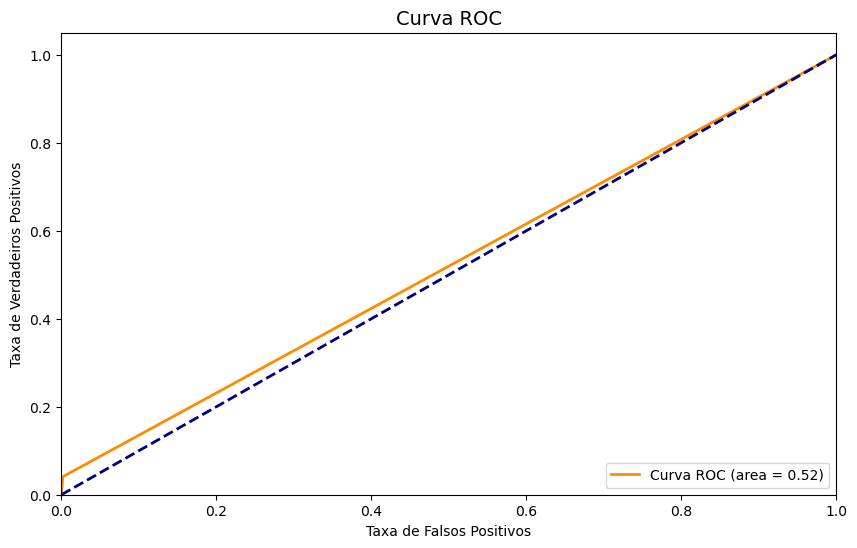

In [159]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_p_roc_auc_select_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O modelo utilizando o kernel='poly' no cenário de variáveis selecionadas (sem padronização e sem balanceamento) resultou no pior desempenho técnico do projeto, consolidando uma Acurácia de 0.63, Média da Validação Cruzada de 0.63 e uma AUC-ROC de apenas 0.52

- **O Colapso do Espaço Polinomial Bruto:** A combinação de transformações polinomiais não-lineares com variáveis em escalas discrepantes (como `Fare` não padronizada) distorceu completamente a geometria dos dados. O modelo falhou em encontrar qualquer padrão de separação útil, agindo de forma quase aleatória para distinguir os perfis.
- **Incapacidade Crítica de Classificação (Recall Mínimo):** O modelo ignorou quase por completo a classe de sobreviventes, registrando um Recall catastrófico de 0.04 e um F1-Score de 0.08 para a Classe 1. A matriz de confusão evidencia esse colapso ao acumular 328 falsos negativos, rotulando quase todos os passageiros como mortos para inflar artificialmente a acurácia global com base na classe majoritária.

##### Aplicação de hiperparâmetros no SVM com os dados selecionados e desbalanceados

In [34]:
# Criação do pipeline para o modelo SVM selecionado
pipeline_svm_select_d = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

In [35]:
# Definição de hiperparâmetros para testes
param_grid_svm_select_d = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1],
        'svc__degree': [2, 3, 4]
    }
]

In [36]:
# Configuração do Grid Search
grid_search_svm_select_d = GridSearchCV(
    estimator=pipeline_svm_select_d,
    param_grid=param_grid_svm_select_d,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

In [37]:
# Executando o Grid Search
grid_search_svm_select_d.fit(X_train_select, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             n_jobs=-1,
             param_grid=[{'svc__C': [0.01, 0.1, 1, 10, 100],
                          'svc__kernel': ['linear']},
                         {'svc__C': [0.1, 1, 10, 100],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
                          'svc__kernel': ['rbf']},
                         {'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3, 4],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1],
                          'svc__kernel': ['poly']}],
             scoring='roc_auc')

In [38]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_svm_select_d.best_params_)
print("Melhor score:", grid_search_svm_select_d.best_score_)

Melhores parâmetros: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Melhor score: 0.8326836799919228


In [39]:
# Treinamento do modelo com os melhores hiperparâmetros
best_svm_select_d = grid_search_svm_select_d.best_estimator_
best_svm_select_d.fit(X_train_select, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC(C=0.1))])

In [ ]:
# Previsão do modelo na base de treino selecionado com os melhores hiperpâmetros
y_svm_train_pred_select_d_best = best_svm_select_d.predict(X_train_select)

In [41]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_d_best = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_select_d_best = cross_val_score(best_svm_select_d, X_train_select, y_train, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, desbalanceados e com aplicação de hiperparâmetros
svm_accuracy_select_d_best = accuracy_score(y_train, y_svm_train_pred_select_d_best)
svm_report_select_d_best = classification_report(y_train, y_svm_train_pred_select_d_best)
svm_confusion_matrix_select_d_best = confusion_matrix(y_train, y_svm_train_pred_select_d_best)
svm_pontuacoes_select_d_best = cross_val_score(best_svm_select_d, X_train_select, y_train, cv=crossvalidation_select_d_best)

print("RESULTADOS: SUPPORT VECTOR MACHINE (SELECIONADOS, DESBALANCEADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia do modelo SVM com os melhores hiperpâmetros: {svm_accuracy_select_d_best:.2f}')
print('---' * 20)
print(f'Relatório de classificação SVM com os melhores hiperpâmetros: \n {svm_report_select_d_best}')
print('---' * 20)
print(f'Matriz de confusão SVM com os melhores hiperpâmetros: \n {svm_confusion_matrix_select_d_best}')
print('---' * 20)
print(f'Média das pontuações do cross validation SVM com os melhores hiperpâmetros: {svm_pontuacoes_select_d_best.mean():.2f}')

Acurácia do modelo SVM com os melhores hiperpâmetros: 0.77
------------------------------------------------------------
Relatório de classificação SVM com os melhores hiperpâmetros: 
               precision    recall  f1-score   support

           0       0.85      0.76      0.80       549
           1       0.67      0.79      0.73       342

    accuracy                           0.77       891
   macro avg       0.76      0.77      0.77       891
weighted avg       0.78      0.77      0.77       891

------------------------------------------------------------
Matriz de confusão SVM com os melhores hiperpâmetros: 
 [[419 130]
 [ 73 269]]
------------------------------------------------------------
Média das pontuações do cross validation SVM com os melhores hiperpâmetros: 0.77


In [43]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train, y_svm_train_pred_select_d_best)

# Cálculo da AUC
roc_auc_select_d_best = roc_auc_score(y_train, y_svm_train_pred_select_d_best)
print('AUC: {:.2f}'.format(roc_auc_select_d_best))

AUC: 0.77


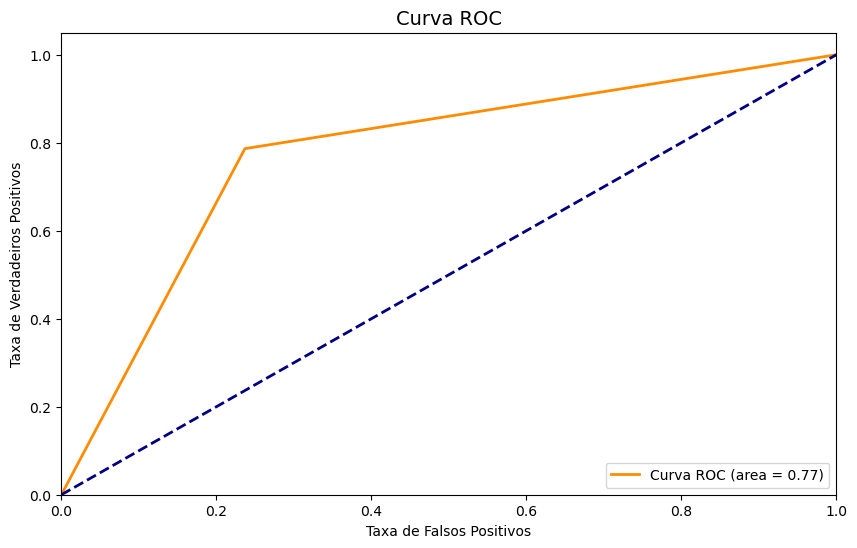

In [44]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_select_d_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A otimização via GridSearchCV para o cenário de variáveis selecionadas identificou a combinação ideal com kernel='rbf', C=0.1 e gamma='scale'. O modelo alcançou uma Acurácia de 0.77, Média da Validação Cruzada de 0.77 e AUC-ROC de 0.77.

- **Máxima Estabilidade Estatística:** A convergência exata entre a acurácia de treino (0.77) e a média da validação cruzada (0.77) comprova que o modelo atingiu uma estabilidade ideal. O valor baixo de regularização (C=0.1) atuou de forma eficiente para simplificar a fronteira geométrica, eliminando qualquer risco de overfitting (sobreajuste).
- **Comportamento Inverso de Sensibilidade:** Diferente de outros modelos do projeto, este SVM apresentou um perfil mais sensível à classe de sobreviventes, registrando um Recall robusto de 0.79 para a Classe 1 (identificando 269 sobreviventes). O trade-off dessa sensibilidade foi o aumento de falsos positivos (130 não-sobreviventes classificados incorretamente), o que resultou em um F1-Score equilibrado de 0.73 para a classe minoritária e 0.80 para a majoritária. Embora estável, este cenário filtrado performou ligeiramente abaixo do SVM RBF com a base completa padronizada (que atingiu acurácia de 0.86).

##### Dados selecionados, balanceados, padronizados (aplicados no kernels=["rbf", "linear" e "poly"]) e com os melhores hiperparâmetros

###### Kernel = 'rbf'

In [ ]:
# Inicialização do modelo SVM balanceado, padronizado e selecionado com Kernel = 'rbf'
svm_rbf_model_select = SVC(kernel='rbf', random_state=42, C=1.0)

In [46]:
# Treinamento do modelo na base de treino balanceado, padronizado e selecionado
svm_rbf_model_select.fit(X_train_select_padro, y_train_balanced)

SVC(random_state=42)

In [47]:
# Previsão do modelo na base de treino balanceado, padronizado e selecionado
y_svm_rbf_train_pred_select = svm_rbf_model_select.predict(X_train_select_padro)

In [48]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_rbf_select = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_rbf_media_final_select = cross_val_score(svm_rbf_model_select, X_train_select_padro, y_train_balanced, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'rbf
svm_rbf_accuracy_select = accuracy_score(y_train_balanced, y_svm_rbf_train_pred_select)
svm_rbf_report_select = classification_report(y_train_balanced, y_svm_rbf_train_pred_select)
svm_rbf_confusion_matrix_select = confusion_matrix(y_train_balanced, y_svm_rbf_train_pred_select)
svm_rbf_pontuacoes_select = cross_val_score(svm_rbf_model_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_rbf_select)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'rbf' (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_rbf_accuracy_select:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_rbf_report_select}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_rbf_confusion_matrix_select}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_rbf_pontuacoes_select.mean():.2f}')

Acurácia do modelo SVM: 0.81
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.81      0.82      0.81       549
           1       0.82      0.80      0.81       549

    accuracy                           0.81      1098
   macro avg       0.81      0.81      0.81      1098
weighted avg       0.81      0.81      0.81      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[450  99]
 [109 440]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.79


In [50]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_rbf_train_pred_select)

# Cálculo da AUC
svm_rbf_roc_auc_select = roc_auc_score(y_train_balanced, y_svm_rbf_train_pred_select)
print('AUC: {:.2f}'.format(svm_rbf_roc_auc_select))

AUC: 0.81


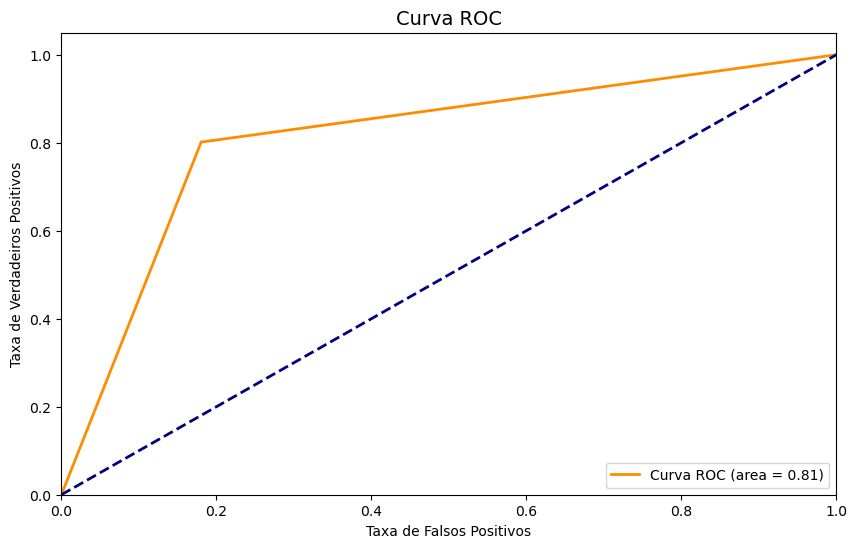

In [51]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_rbf_roc_auc_select)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A introdução das técnicas de padronização e balanceamento amostral para o modelo SVM RBF com as variáveis selecionadas resultou em um desempenho sólido, consolidando uma Acurácia de 0.81, Média da Validação Cruzada de 0.79 e uma AUC-ROC de 0.81.

- **Correção do Viés Espacial:** Colocar as colunas na mesma escala estatística permitiu que o kernel RBF mapeasse corretamente a fronteira geométrica no cenário reduzido. O balanceamento eliminou a tendência anterior de favorecer a classe majoritária, estabelecendo um F1-Score idêntico e equilibrado de 0.81 para ambas as classes.
- **Estabilidade Preditiva Elevada:** A proximidade estreita entre o treino (0.81) e a validação cruzada (0.79) indica ótima capacidade de generalização e ausência de overfitting. A matriz de confusão demonstra uma distribuição simétrica de erros (99 falsos positivos e 109 falsos negativos), mostrando que a filtragem por correlação gerou um modelo enxuto, estável e competitivo, embora ligeiramente inferior ao teto de 0.86 atingido pelo SVM RBF na base completa tratada.

###### Kernel = 'linear'

In [52]:
# Inicialização do modelo SVM balanceado, padronizado e selecionado com Kernel = 'linear'
svm_l_model_select = SVC(kernel='linear', random_state=42, C=1.0)

In [53]:
# Treinamento do modelo na base de treino balanceado, padronizado e selecionado
svm_l_model_select.fit(X_train_select_padro, y_train_balanced)

SVC(kernel='linear', random_state=42)

In [54]:
# Previsão do modelo na base de treino balanceado, padronizado e selecionado
y_svm_l_train_pred_select = svm_l_model_select.predict(X_train_select_padro)

In [55]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_l_select = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_l_media_final_select = cross_val_score(svm_l_model_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_l_select)

In [ ]:
# Avaliação do modelo SVM com dados completos, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'linear'
svm_l_accuracy_select = accuracy_score(y_train_balanced, y_svm_l_train_pred_select)
svm_l_report_select = classification_report(y_train_balanced, y_svm_l_train_pred_select)
svm_l_confusion_matrix_select = confusion_matrix(y_train_balanced, y_svm_l_train_pred_select)
svm_l_pontuacoes_select = cross_val_score(svm_l_model_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_l_select)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'linear' (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_l_accuracy_select:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_l_report_select}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_l_confusion_matrix_select}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_l_pontuacoes_select.mean():.2f}')

Acurácia do modelo SVM: 0.80
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.78      0.83      0.80       549
           1       0.82      0.77      0.79       549

    accuracy                           0.80      1098
   macro avg       0.80      0.80      0.80      1098
weighted avg       0.80      0.80      0.80      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[453  96]
 [125 424]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.79


In [57]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_l_train_pred_select)

# Cálculo da AUC
svm_l_roc_auc_select = roc_auc_score(y_train_balanced, y_svm_l_train_pred_select)
print('AUC: {:.2f}'.format(svm_l_roc_auc_select))

AUC: 0.80


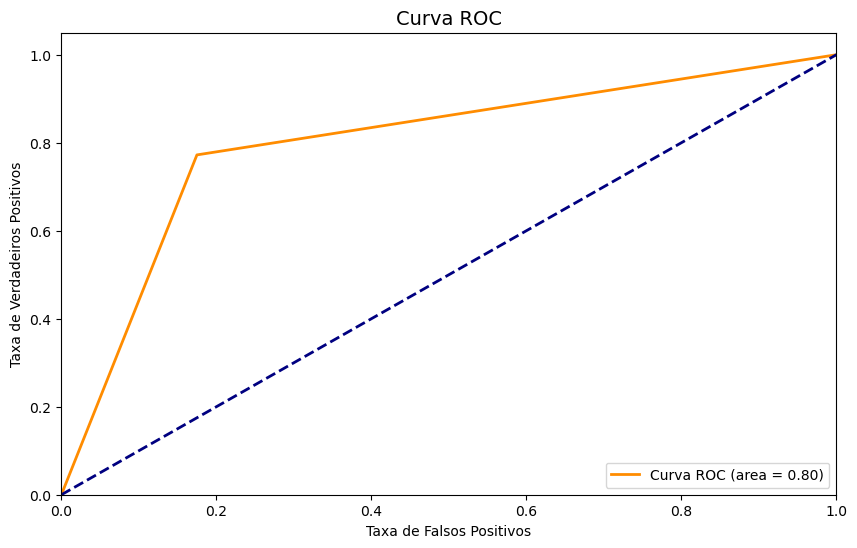

In [58]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_l_roc_auc_select)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O modelo utilizando o kernel='linear' com o conjunto reduzido de variáveis (selecionadas por correlação), padronizadas e balanceadas, alcançou um desempenho estatisticamente sólido e previsível, consolidando uma Acurácia de 0.80, Média da Validação Cruzada de 0.79 e AUC-ROC de 0.80, como evidenciado no gráfico enviado.

- **Alta Capacidade de Generalização:** A diferença mínima de apenas um ponto percentual entre a acurácia de treino (0.80) e a validação cruzada (0.79) indica estabilidade absoluta. O modelo linear não sofre com sobreajuste (overfitting), demonstrando que a fronteira linear encontrada é altamente reprodutível.
- **Equilíbrio Entre as Classes:** Graças às técnicas de tratamento e balanceamento amostral, o classificador obteve métricas homogêneas, com um F1-Score de 0.80 para não-sobreviventes e 0.79 para sobreviventes. A matriz de confusão apresenta um comportamento controlado (96 falsos positivos e 125 falsos negativos). Embora confiável, o kernel linear manteve-se ligeiramente abaixo do teto não-linear do kernel RBF na base completa (0.86), sugerindo que as interações complexas entre as variáveis originais dão uma ligeira vantagem a separações curvilíneas.

###### Kernel = 'poly'

In [59]:
# Inicialização do modelo SVM balanceado, padronizado e selecionado com Kernel = 'poly'
svm_p_model_select = SVC(kernel='poly', random_state=42, C=1.0)

In [60]:
# Treinamento do modelo na base de treino balanceado, padronizado e selecionado
svm_p_model_select.fit(X_train_select_padro, y_train_balanced)

SVC(kernel='poly', random_state=42)

In [61]:
# Previsão do modelo na base de treino balanceado, padronizado e selecionado
y_svm_p_train_pred_select = svm_p_model_select.predict(X_train_select_padro)

In [62]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_p_select = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_p_media_final_select = cross_val_score(svm_p_model_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_p_select)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, balanceados, padronizados e com aplicação de hiperparâmetros Kernel = 'poly'
svm_p_accuracy_select = accuracy_score(y_train_balanced, y_svm_p_train_pred_select)
svm_p_report_select = classification_report(y_train_balanced, y_svm_p_train_pred_select)
svm_p_confusion_matrix_select = confusion_matrix(y_train_balanced, y_svm_p_train_pred_select)
svm_p_pontuacoes_select = cross_val_score(svm_p_model_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_p_select)

print("RESULTADOS: SUPPORT VECTOR MACHINE KERNEL = 'poly' (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_p_accuracy_select:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_p_report_select}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_p_confusion_matrix_select}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_p_pontuacoes_select.mean():.2f}')

Acurácia do modelo SVM: 0.81
------------------------------------------------------------
Relatório de classificação SVM: 
               precision    recall  f1-score   support

           0       0.80      0.84      0.82       549
           1       0.83      0.79      0.81       549

    accuracy                           0.81      1098
   macro avg       0.81      0.81      0.81      1098
weighted avg       0.81      0.81      0.81      1098

------------------------------------------------------------
Matriz de confusão SVM: 
 [[461  88]
 [117 432]]
------------------------------------------------------------
Média das pontuações do cross validation SVM: 0.80


In [64]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_p_train_pred_select)

# Cálculo da AUC
svm_p_roc_auc_select = roc_auc_score(y_train_balanced, y_svm_p_train_pred_select)
print('AUC: {:.2f}'.format(svm_p_roc_auc_select))

AUC: 0.81


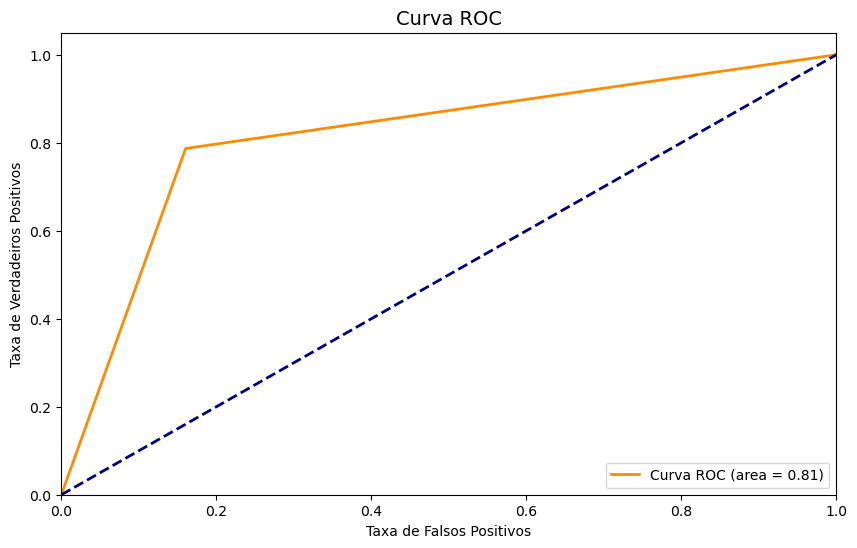

In [66]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % svm_p_roc_auc_select)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
O modelo utilizando o kernel='poly' (Polinomial) com o conjunto reduzido de variáveis selecionadas por correlação, devidamente padronizadas e balanceadas, demonstrou uma evolução substancial, atingindo uma Acurácia de 0.81, Média da Validação Cruzada de 0.80 e AUC-ROC de 0.81.

- **Recuperação Eficiente do Kernel Polinomial:** Diferente do cenário polinomial bruto (que colapsou em 0.63 de acurácia por falta de escala), a aplicação do tratamento amostral permitiu que o modelo operasse corretamente. O balanceamento eliminou o viés anterior, consolidando um F1-Score altamente equilibrado de 0.82 para não-sobreviventes e 0.81 para sobreviventes.
- **Consistência Estatística e Generalização:** A margem mínima entre o treino (0.81) e a validação cruzada (0.80) atesta a ausência de overfitting e valida a estabilidade da fronteira não-linear. A matriz de confusão apresenta um comportamento simétrico, com 88 falsos positivos e 117 falsos negativos. Embora este modelo empate tecnicamente com o kernel RBF no cenário seletivo, ambos ficam ligeiramente abaixo do teto de 0.86 de acurácia estabelecido pelo SVM RBF no cenário de dados completos e tratados.

##### Aplicação de hiperparâmetros no SVM com os dados selecionados, balanceados e padronizados

In [67]:
# Criação do pipeline para o modelo SVM selecionado
pipeline_svm_select = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

In [69]:
# Definição de hiperparâmetros para testes
param_grid_svm_select = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.1, 1, 10, 100],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.1, 1, 10],
        'svc__gamma': ['scale', 'auto', 0.01, 0.1],
        'svc__degree': [2, 3, 4]
    }
]

In [70]:
# Configuração do Grid Search
grid_search_svm_select = GridSearchCV(
    estimator=pipeline_svm_select,
    param_grid=param_grid_svm_select,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

In [72]:
# Executando o Grid Search
grid_search_svm_select.fit(X_train_select_padro, y_train_balanced)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             n_jobs=-1,
             param_grid=[{'svc__C': [0.01, 0.1, 1, 10, 100],
                          'svc__kernel': ['linear']},
                         {'svc__C': [0.1, 1, 10, 100],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1],
                          'svc__kernel': ['rbf']},
                         {'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3, 4],
                          'svc__gamma': ['scale', 'auto', 0.01, 0.1],
                          'svc__kernel': ['poly']}],
             scoring='roc_auc')

In [73]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_svm_select.best_params_)
print("Melhor score:", grid_search_svm_select.best_score_)

Melhores parâmetros: {'svc__C': 0.1, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Melhor score: 0.8566851163848662


In [74]:
# Treinamento do modelo com os melhores hiperparâmetros
best_svm_select = grid_search_svm_select.best_estimator_
best_svm_select.fit(X_train_select_padro, y_train_balanced)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC(C=0.1, gamma=0.01))])

In [75]:
# Previsão do modelo na base de treino selecionado com os melhores hiperpâmetros
y_svm_train_pred_select_best = best_svm_select.predict(X_train_select_padro)

In [76]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_select_best = KFold(n_splits=folds, shuffle=True, random_state=5)
svm_media_final_select_best = cross_val_score(best_svm_select, X_train_select_padro, y_train_balanced, cv=folds)

In [ ]:
# Avaliação do modelo SVM com dados selecionados, balanceados, padronizados e com aplicação de hiperparâmetros
svm_accuracy_select_best = accuracy_score(y_train_balanced, y_svm_train_pred_select_best)
svm_report_select_best = classification_report(y_train_balanced, y_svm_train_pred_select_best)
svm_confusion_matrix_select_best = confusion_matrix(y_train_balanced, y_svm_train_pred_select_best)
svm_pontuacoes_select_best = cross_val_score(best_svm_select, X_train_select_padro, y_train_balanced, cv=crossvalidation_select_best)

print("RESULTADOS: SUPPORT VECTOR MACHINE (SELECIONADOS, BALANCEADO, PADRONIZADO E COM HIPERPARÂMETROS)")
print('---' * 20)
print(f'Acurácia: {svm_accuracy_select_best:.2f}')
print('---' * 20)
print(f'Relatório de Classificação: \n {svm_report_select_best}')
print('---' * 20)
print(f'Matriz de Confusão: \n {svm_confusion_matrix_select_best}')
print('---' * 20)
print(f'Média da Validação Cruzada: {svm_pontuacoes_select_best.mean():.2f}')

Acurácia do modelo SVM com os melhores hiperpâmetros: 0.80
------------------------------------------------------------
Relatório de classificação SVM com os melhores hiperpâmetros: 
               precision    recall  f1-score   support

           0       0.78      0.83      0.81       549
           1       0.82      0.77      0.79       549

    accuracy                           0.80      1098
   macro avg       0.80      0.80      0.80      1098
weighted avg       0.80      0.80      0.80      1098

------------------------------------------------------------
Matriz de confusão SVM com os melhores hiperpâmetros: 
 [[456  93]
 [127 422]]
------------------------------------------------------------
Média das pontuações do cross validation SVM com os melhores hiperpâmetros: 0.79


In [79]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train_balanced, y_svm_train_pred_select_best)

# Cálculo da AUC
roc_auc_select_best = roc_auc_score(y_train_balanced, y_svm_train_pred_select_best)
print('AUC: {:.2f}'.format(roc_auc_select_best))

AUC: 0.80


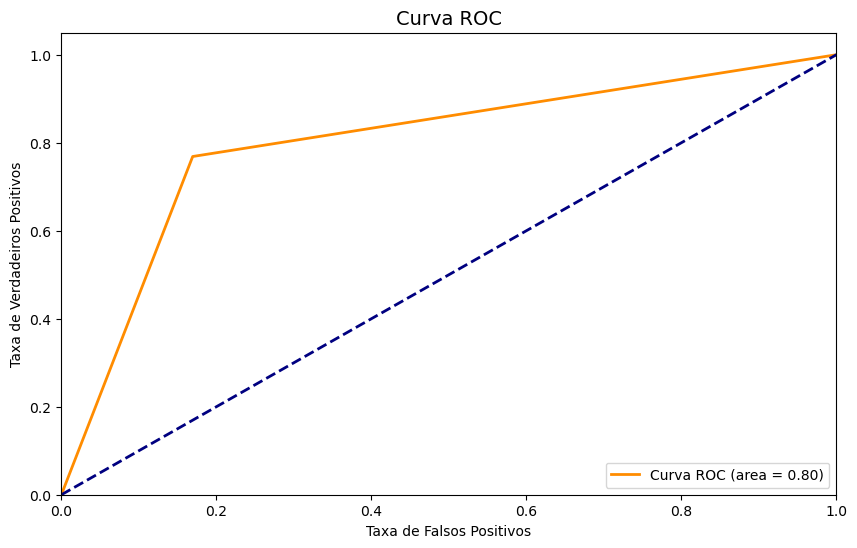

In [80]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_select_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A otimização via GridSearchCV no cenário seletivo encontrou sua melhor configuração com kernel='rbf', C=0.1 e gamma=0.01. O modelo consolidou uma Acurácia de 0.80, Média da Validação Cruzada de 0.79 e uma AUC-ROC de 0.80.

- **Máxima Robustez e Controle de Variância:** A combinação de uma forte regularização (C=0.1) com um raio de influência suavizado (gamma=0.01) simplificou a fronteira de decisão geométrica. Como a acurácia de treino (0.80) e a validação cruzada (0.79) convergiram quase perfeitamente, o modelo comprova estar totalmente imune ao overfitting, garantindo alta confiabilidade estatística.
- **Simetria Preditiva:** O tratamento conjunto de balanceamento e sintonia fina eliminou discrepâncias entre as classes, entregando um F1-Score altamente equilibrado de 0.81 para não-sobreviventes e 0.79 para sobreviventes. Embora o filtro de correlação tenha gerado uma estrutura enxuta e estável, o teto de acurácia deste modelo (0.80) ficou abaixo do pico de performance alcançado pelo SVM RBF no cenário completo tratado (0.86), evidenciando que o descarte de variáveis reduziu a capacidade preditiva máxima do algoritmo.

### Comparação entre modelos

**MELHORIAS PARA SEREM APLICADAS** \
1 - Aplicar melhorias nos textos de avaliação de todos os modelos; \
2 - Obter as variáveis que são mais importante para depois gerar tabela comparando elas.

**RANDOM FOREST**

**Cenário completo**
- DADOS COMPLETOS, DESBALANCEADOS E DESPADRONIZADOS = CV [pontuacoes_complet_dp], Acurácia [accuracy_complet_dp] e F1-Score [report_rf__complet_dict_dp = classification_report(y_train, y_rf_train_pred_complet_dp, output_dict=True); f1_rf_complet_dp = report_rf__complet_dict_dp['macro avg']['f1-score']];
- DADOS COMPLETOS, DESBALANCEADOS E DESPADRONIZADOS COM APLICAÇÃO DE HIPERPARÂMETROS = CV [pontuacoes_complet_dp_best], Acurácia [accuracy_complet_dp_best], F1-Score [report_rf_complet_dict_dp_best = classification_report(y_train, y_rf_train_pred_complet_dp_best, output_dict=True); f1_rf_complet_dp_best = report_rf_complet_dict_dp_best['macro avg']['f1-score']];
- DADOS COMPLETOS, BALANCEADOS E PADRONIZADOS COM APLICAÇÃO DE HIPERPARÂMETROS = CV [pontuacoes_complet_best], Acurácia [accuracy_complet_best] e F1-Score [report_rf_complet_dict_best = classification_report(y_train_balanced, y_rf_train_pred_complet_best, output_dict=True); f1_rf_complet_best = report_rf_complet_dict_best['macro avg']['f1-score']];

**Cenário selecionado**
- DADOS SELECIONADOS, DESBALANCEADOS E DESPADRONIZADOS = CV [pontuacoes_select_dp], Acurácia [accuracy_select_dp] e F1-Score [report_rf_select_dict_dp = classification_report(y_train, y_rf_train_pred_select_dp, output_dict=True); f1_rf_select_dp = report_rf_complet_dict_best['macro avg']['f1-score']];
- DADOS SELECIONADOS, DESBALANCEADOS E DESPADRONIZADOS COM APLICAÇÃO DE HIPERPARÂMETROS = CV [pontuacoes_select_dp_best], Acurácia [accuracy_select_dp_best] e F1-Score [report_rf_select_dict_dp_best = classification_report(y_train, y_rf_train_pred_select_dp_best, output_dict=True); f1_rf_select_dp_best = report_rf_select_dict_dp_best['macro avg']['f1-score']];
- DADOS SELECIONADOS, BALANCEADOS E PADRONIZADOS COM APLICAÇÃO DE HIPERPARÂMETROS = CV [pontuacoes_select_best], Acurácia [accuracy_select_best] e F1-Score [report_rf_select_dict_best = classification_report(y_train_balanced, y_rf_train_pred_select_best, output_dict=True); f1_rf_select_best = report_rf_select_dict_best['macro avg']['f1-score']].

**SVM**
**Cenário completo**
**Dados desbalanceados e despadronizados**
- Kernel = "rbf" = CV [], Acurácia [] e F1-Score [];
- Kernel = "linear" = CV [], Acurácia [] e F1-Score [];
- Kernel = "poly" = CV [], Acurácia [] e F1-Score [];
- Aplicação de hiperparâmetros no SVM com os dados completos e desbalanceados = CV [], Acurácia [] e F1-Score [];
**Dados balanceados, padronizados (aplicado nos kernels=["rbf", "linear" e "poly"]) e com os melhores hiperparâmetros**
- Kernel = "rbf" = CV [], Acurácia [] e F1-Score [];
- Kernel = "linear" = CV [], Acurácia [] e F1-Score [];
- Kernel = "poly" = CV [], Acurácia [] e F1-Score [];
- Aplicação de hiperparâmetros no SVM com os dados desbalanceados e padronizados = CV [], Acurácia [] e F1-Score [];

**Cenário selecionado**
**Dados desbalanceados e despadronizados**
- Kernel = "rbf" = CV [], Acurácia [] e F1-Score [];
- Kernel = "linear" = CV [], Acurácia [] e F1-Score [];
- Kernel = "poly" = CV [], Acurácia [] e F1-Score [];
- Aplicação de hiperparâmetros no SVM com os dados completos e desbalanceados = CV [], Acurácia [] e F1-Score [];
**Dados balanceados, padronizados (aplicado nos kernels=["rbf", "linear" e "poly"]) e com os melhores hiperparâmetros**
- Kernel = "rbf" = CV [], Acurácia [] e F1-Score [];
- Kernel = "linear" = CV [], Acurácia [] e F1-Score [];
- Kernel = "poly" = CV [], Acurácia [] e F1-Score [];
- Aplicação de hiperparâmetros no SVM com os dados desbalanceados e padronizados = CV [], Acurácia [] e F1-Score [].

## CONCLUSÃO